In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


In [2]:
data=pd.read_csv('household_power_consumption.csv')
data

,index,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,0,1/1/07,0:00:00,2.58,0.136,241.97,10.6,0,0,0.0
1,1,1/1/07,0:01:00,2.552,0.1,241.75,10.4,0,0,0.0
2,2,1/1/07,0:02:00,2.55,0.1,241.64,10.4,0,0,0.0
3,3,1/1/07,0:03:00,2.55,0.1,241.71,10.4,0,0,0.0
4,4,1/1/07,0:04:00,2.554,0.1,241.98,10.4,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...
260635,260635,30/6/2007,23:55:00,2.88,0.36,239.01,12,0,0,18.0
260636,260636,30/6/2007,23:56:00,2.892,0.358,238.86,12.2,0,0,17.0
260637,260637,30/6/2007,23:57:00,2.882,0.28,239.05,12,0,0,18.0
260638,260638,30/6/2007,23:58:00,2.66,0.29,238.98,11.2,0,0,18.0


In [3]:
# Step 1: Fix single-digit days and months
sample_dates_before = data['Date'].head(20)
print("Sample Dates before fixing:")
print(sample_dates_before)
data['Date'] = data['Date'].apply(lambda x: '/'.join([part.zfill(2) if i < 2 else part for i, part in enumerate(x.split('/'))]))

# Step 2: Fix two-digit years (e.g., 07 -> 2007)
data['Date'] = data['Date'].apply(lambda x: x[:6] + '20' + x[6:] if len(x.split('/')[2]) == 2 else x)

# Sample of dates before and after fixing
sample_dates_after = data['Date'].head(20)

print("Sample Dates after fixing:")
print(sample_dates_after)


Sample Dates before fixing:
0     1/1/07
1     1/1/07
2     1/1/07
3     1/1/07
4     1/1/07
5     1/1/07
6     1/1/07
7     1/1/07
8     1/1/07
9     1/1/07
10    1/1/07
11    1/1/07
12    1/1/07
13    1/1/07
14    1/1/07
15    1/1/07
16    1/1/07
17    1/1/07
18    1/1/07
19    1/1/07
Name: Date, dtype: object
Sample Dates after fixing:
0     01/01/2007
1     01/01/2007
2     01/01/2007
3     01/01/2007
4     01/01/2007
5     01/01/2007
6     01/01/2007
7     01/01/2007
8     01/01/2007
9     01/01/2007
10    01/01/2007
11    01/01/2007
12    01/01/2007
13    01/01/2007
14    01/01/2007
15    01/01/2007
16    01/01/2007
17    01/01/2007
18    01/01/2007
19    01/01/2007
Name: Date, dtype: object


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260640 entries, 0 to 260639
Data columns (total 10 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   index                  260640 non-null  int64  
 1   Date                   260640 non-null  object 
 2   Time                   260640 non-null  object 
 3   Global_active_power    260640 non-null  object 
 4   Global_reactive_power  260640 non-null  object 
 5   Voltage                260640 non-null  object 
 6   Global_intensity       260640 non-null  object 
 7   Sub_metering_1         260640 non-null  object 
 8   Sub_metering_2         260640 non-null  object 
 9   Sub_metering_3         256869 non-null  float64
dtypes: float64(1), int64(1), object(8)
memory usage: 19.9+ MB


In [5]:
data['Global_active_power'] = pd.to_numeric(data['Global_active_power'], errors='coerce')
data['Global_reactive_power'] = pd.to_numeric(data['Global_reactive_power'], errors='coerce')
data['Voltage'] = pd.to_numeric(data['Voltage'], errors='coerce')
data['Global_intensity'] = pd.to_numeric(data['Global_intensity'], errors='coerce')
data['Sub_metering_1'] = pd.to_numeric(data['Sub_metering_1'], errors='coerce')
data['Sub_metering_2'] = pd.to_numeric(data['Sub_metering_2'], errors='coerce')
data['Sub_metering_3'] = pd.to_numeric(data['Sub_metering_3'], errors='coerce')
data.drop(['index'],axis=1,inplace=True)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260640 entries, 0 to 260639
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Date                   260640 non-null  object 
 1   Time                   260640 non-null  object 
 2   Global_active_power    256869 non-null  float64
 3   Global_reactive_power  256869 non-null  float64
 4   Voltage                256869 non-null  float64
 5   Global_intensity       256869 non-null  float64
 6   Sub_metering_1         256869 non-null  float64
 7   Sub_metering_2         256869 non-null  float64
 8   Sub_metering_3         256869 non-null  float64
dtypes: float64(7), object(2)
memory usage: 17.9+ MB


In [6]:
# Convert Date and Time columns into a single datetime column
data['Datetime'] = pd.to_datetime(data['Date'] + ' ' + data['Time'], format='%d/%m/%Y %H:%M:%S', dayfirst=True)

# Drop the original Date and Time columns
data.drop(columns=['Date', 'Time'], inplace=True)

# Check the result
data.head()


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime
0,2.580,0.136,241.97,10.6,0.0,0.0,0.0,2007-01-01 00:00:00
1,2.552,0.100,241.75,10.4,0.0,0.0,0.0,2007-01-01 00:01:00
2,2.550,0.100,241.64,10.4,0.0,0.0,0.0,2007-01-01 00:02:00
3,2.550,0.100,241.71,10.4,0.0,0.0,0.0,2007-01-01 00:03:00
4,2.554,0.100,241.98,10.4,0.0,0.0,0.0,2007-01-01 00:04:00


In [7]:
# بررسی تعداد مقادیر گمشده در هر ستون
missing_values = data.isnull().sum()

# نمایش مقادیر گمشده
missing_values[missing_values > 0]


Global_active_power      3771
Global_reactive_power    3771
Voltage                  3771
Global_intensity         3771
Sub_metering_1           3771
Sub_metering_2           3771
Sub_metering_3           3771
dtype: int64

In [8]:

data.dropna(inplace=True)
data.reset_index(drop=True, inplace=True)

data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 256869 entries, 0 to 256868
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   Global_active_power    256869 non-null  float64       
 1   Global_reactive_power  256869 non-null  float64       
 2   Voltage                256869 non-null  float64       
 3   Global_intensity       256869 non-null  float64       
 4   Sub_metering_1         256869 non-null  float64       
 5   Sub_metering_2         256869 non-null  float64       
 6   Sub_metering_3         256869 non-null  float64       
 7   Datetime               256869 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(7)
memory usage: 15.7 MB


In [9]:
data

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime
0,2.580,0.136,241.97,10.6,0.0,0.0,0.0,2007-01-01 00:00:00
1,2.552,0.100,241.75,10.4,0.0,0.0,0.0,2007-01-01 00:01:00
2,2.550,0.100,241.64,10.4,0.0,0.0,0.0,2007-01-01 00:02:00
3,2.550,0.100,241.71,10.4,0.0,0.0,0.0,2007-01-01 00:03:00
4,2.554,0.100,241.98,10.4,0.0,0.0,0.0,2007-01-01 00:04:00
...,...,...,...,...,...,...,...,...
256864,2.880,0.360,239.01,12.0,0.0,0.0,18.0,2007-06-30 23:55:00
256865,2.892,0.358,238.86,12.2,0.0,0.0,17.0,2007-06-30 23:56:00
256866,2.882,0.280,239.05,12.0,0.0,0.0,18.0,2007-06-30 23:57:00
256867,2.660,0.290,238.98,11.2,0.0,0.0,18.0,2007-06-30 23:58:00


In [10]:
data.to_csv('household_power_consumptionpre.csv', index=False)

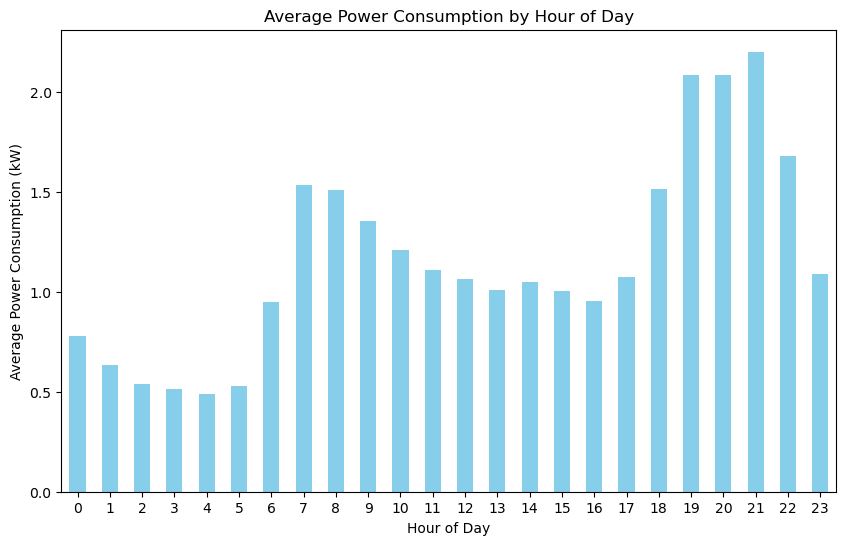

In [11]:

# اضافه کردن یک ستون ساعت به دیتاست
data['Hour'] = data['Datetime'].dt.hour

# گروه‌بندی داده‌ها بر اساس ساعت و محاسبه میانگین مصرف برق
hourly_consumption = data.groupby('Hour')['Global_active_power'].mean()

# رسم نمودار
plt.figure(figsize=(10, 6))
hourly_consumption.plot(kind='bar', color='skyblue')
plt.title('Average Power Consumption by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Power Consumption (kW)')
plt.xticks(rotation=0)
plt.show()


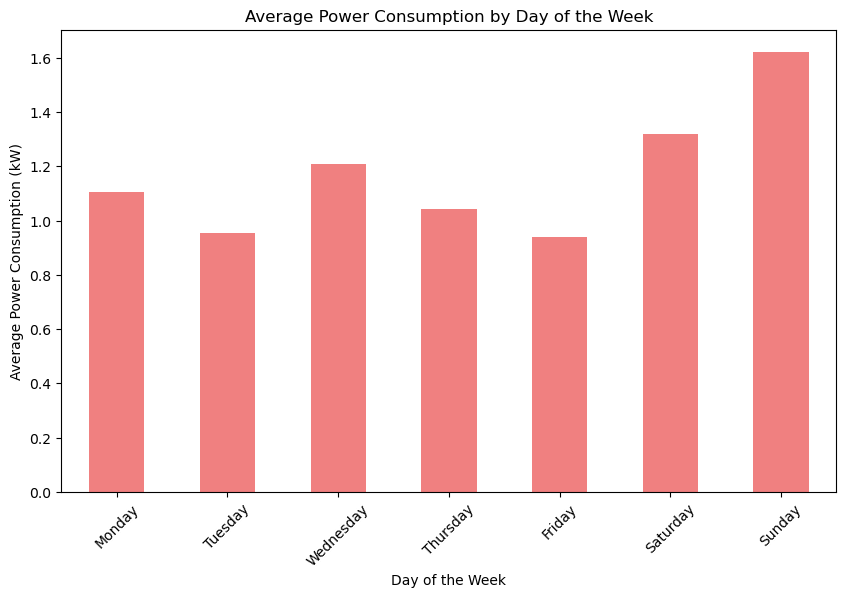

In [12]:
data['DayOfWeek'] = data['Datetime'].dt.day_name()

daily_consumption = data.groupby('DayOfWeek')['Global_active_power'].mean()

ordered_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_consumption = daily_consumption[ordered_days]

# رسم نمودار
plt.figure(figsize=(10, 6))
daily_consumption.plot(kind='bar', color='lightcoral')
plt.title('Average Power Consumption by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Power Consumption (kW)')
plt.xticks(rotation=45)
plt.show()


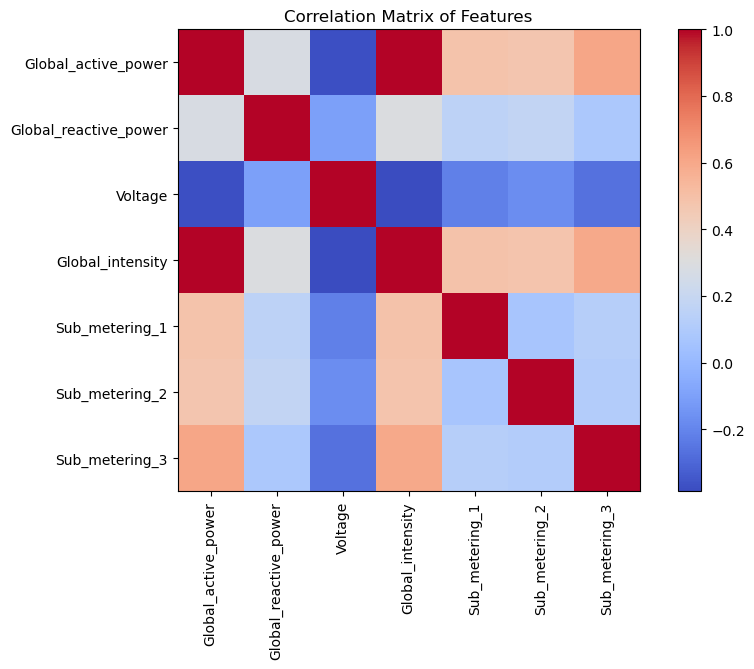

In [13]:
# انتخاب فقط ویژگی‌های عددی برای محاسبه همبستگی
numeric_data = data.select_dtypes(include=['float64', 'int64'])

# محاسبه همبستگی بین ویژگی‌های عددی و مصرف برق
correlation_matrix = numeric_data.corr()

# نمایش ماتریس همبستگی
plt.figure(figsize=(10, 6))
plt.imshow(correlation_matrix, cmap='coolwarm', interpolation='none')
plt.colorbar()
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.title('Correlation Matrix of Features')
plt.show()

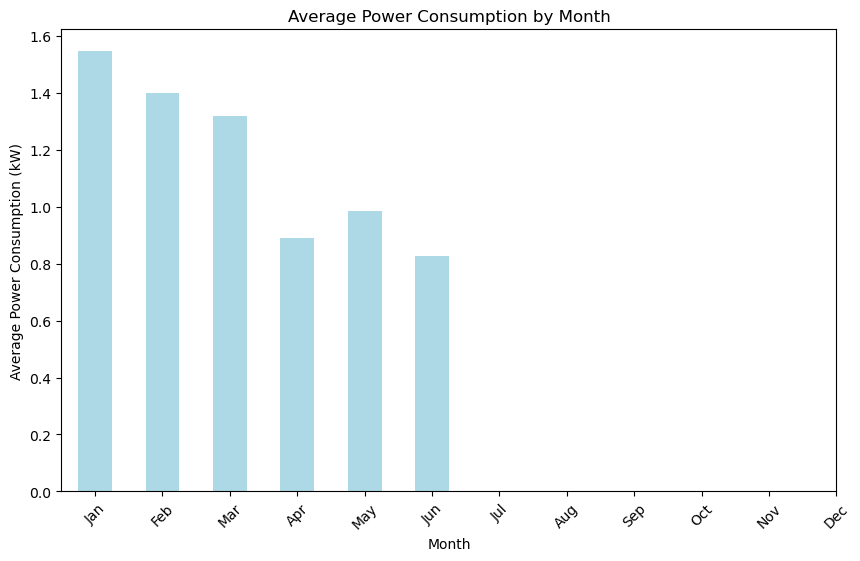

In [14]:
data['Month'] = data['Datetime'].dt.month
# گروه‌بندی داده‌ها بر اساس ماه و محاسبه میانگین مصرف برق
monthly_consumption = data.groupby('Month')['Global_active_power'].mean()
# رسم نمودار
plt.figure(figsize=(10, 6))
monthly_consumption.plot(kind='bar', color='lightblue')
plt.title('Average Power Consumption by Month')
plt.xlabel('Month')
plt.ylabel('Average Power Consumption (kW)')
plt.xticks(ticks=range(12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=45)
plt.show()


In [15]:
data

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Hour,DayOfWeek,Month
0,2.580,0.136,241.97,10.6,0.0,0.0,0.0,2007-01-01 00:00:00,0,Monday,1
1,2.552,0.100,241.75,10.4,0.0,0.0,0.0,2007-01-01 00:01:00,0,Monday,1
2,2.550,0.100,241.64,10.4,0.0,0.0,0.0,2007-01-01 00:02:00,0,Monday,1
3,2.550,0.100,241.71,10.4,0.0,0.0,0.0,2007-01-01 00:03:00,0,Monday,1
4,2.554,0.100,241.98,10.4,0.0,0.0,0.0,2007-01-01 00:04:00,0,Monday,1
...,...,...,...,...,...,...,...,...,...,...,...
256864,2.880,0.360,239.01,12.0,0.0,0.0,18.0,2007-06-30 23:55:00,23,Saturday,6
256865,2.892,0.358,238.86,12.2,0.0,0.0,17.0,2007-06-30 23:56:00,23,Saturday,6
256866,2.882,0.280,239.05,12.0,0.0,0.0,18.0,2007-06-30 23:57:00,23,Saturday,6
256867,2.660,0.290,238.98,11.2,0.0,0.0,18.0,2007-06-30 23:58:00,23,Saturday,6


In [16]:
description = data.describe()


print(description)


       Global_active_power  Global_reactive_power        Voltage  \
count        256869.000000          256869.000000  256869.000000   
mean              1.164937               0.123729     239.208981   
min               0.082000               0.000000     223.490000   
25%               0.296000               0.000000     236.650000   
50%               0.564000               0.104000     239.610000   
75%               1.606000               0.194000     241.810000   
max              10.670000               1.148000     250.890000   
std               1.181832               0.111872       3.592793   

       Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  \
count     256869.000000   256869.000000   256869.000000   256869.000000   
mean           4.974755        1.332481        1.670610        5.831825   
min            0.400000        0.000000        0.000000        0.000000   
25%            1.400000        0.000000        0.000000        0.000000   
50%         

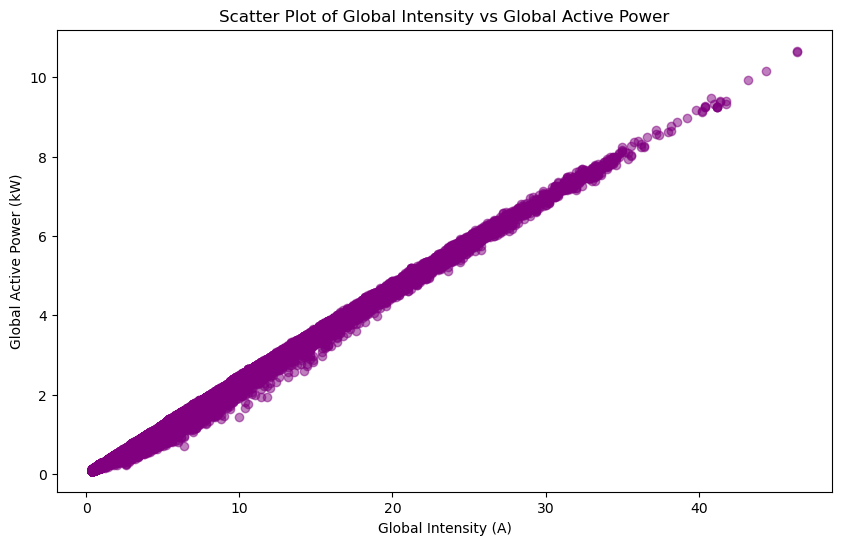

In [17]:
plt.figure(figsize=(10, 6))
plt.scatter(data['Global_intensity'], data['Global_active_power'], alpha=0.5, color='purple')
plt.title('Scatter Plot of Global Intensity vs Global Active Power')
plt.xlabel('Global Intensity (A)')
plt.ylabel('Global Active Power (kW)')
plt.show()


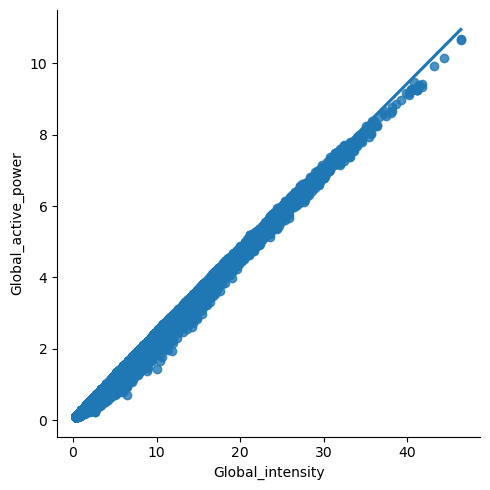

In [18]:
sns.lmplot(x='Global_intensity',y='Global_active_power',data=data)
plt.show()

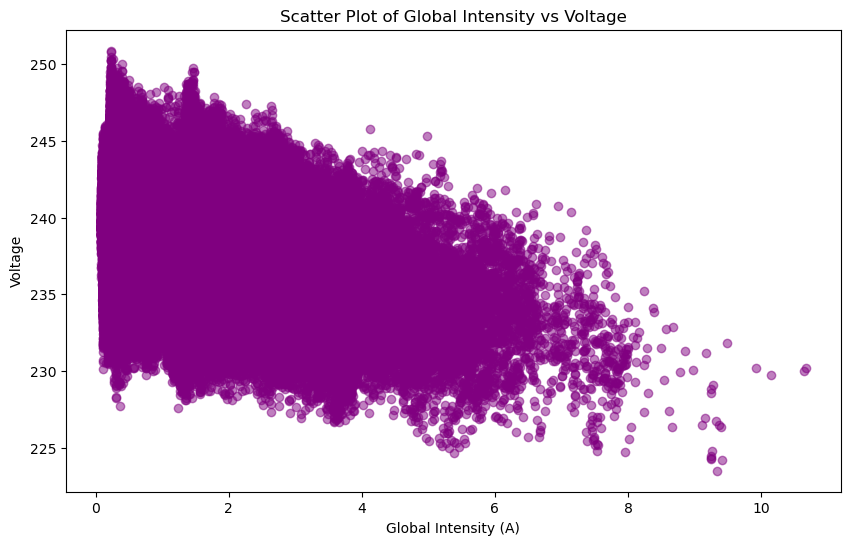

In [19]:
plt.figure(figsize=(10, 6))
plt.scatter(data['Global_active_power'], data['Voltage'], alpha=0.5, color='purple')
plt.title('Scatter Plot of Global Intensity vs Voltage')
plt.xlabel('Global Intensity (A)')
plt.ylabel('Voltage')
plt.show()

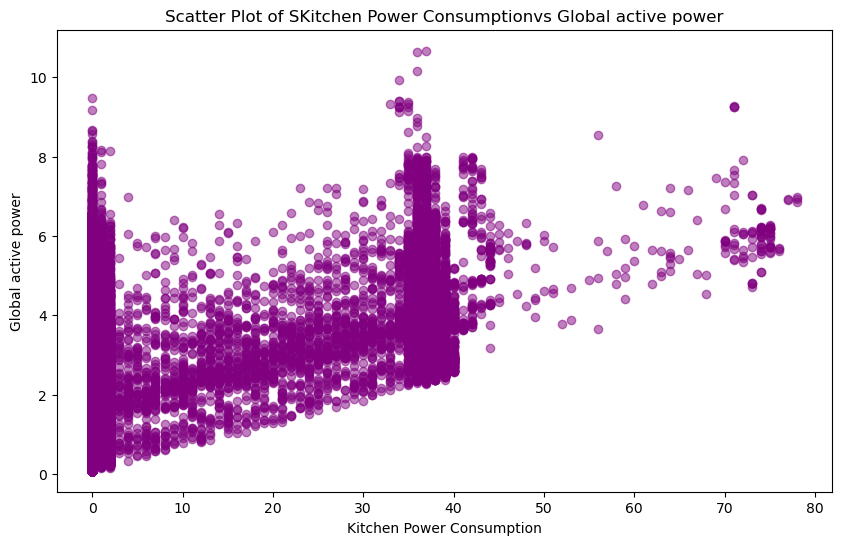

In [20]:
plt.figure(figsize=(10, 6))
plt.scatter(data['Sub_metering_1'], data['Global_active_power'], alpha=0.5, color='purple')
plt.title('Scatter Plot of SKitchen Power Consumptionvs Global active power')
plt.xlabel('Kitchen Power Consumption')
plt.ylabel('Global active power')
plt.show()

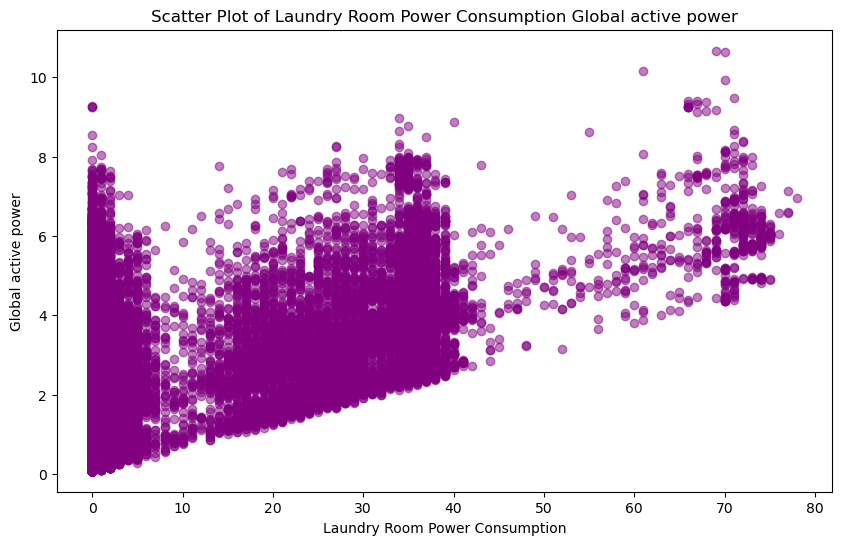

In [21]:
plt.figure(figsize=(10, 6))
plt.scatter(data['Sub_metering_2'], data['Global_active_power'], alpha=0.5, color='purple')
plt.title('Scatter Plot of Laundry Room Power Consumption Global active power')
plt.xlabel('Laundry Room Power Consumption')
plt.ylabel('Global active power')
plt.show()

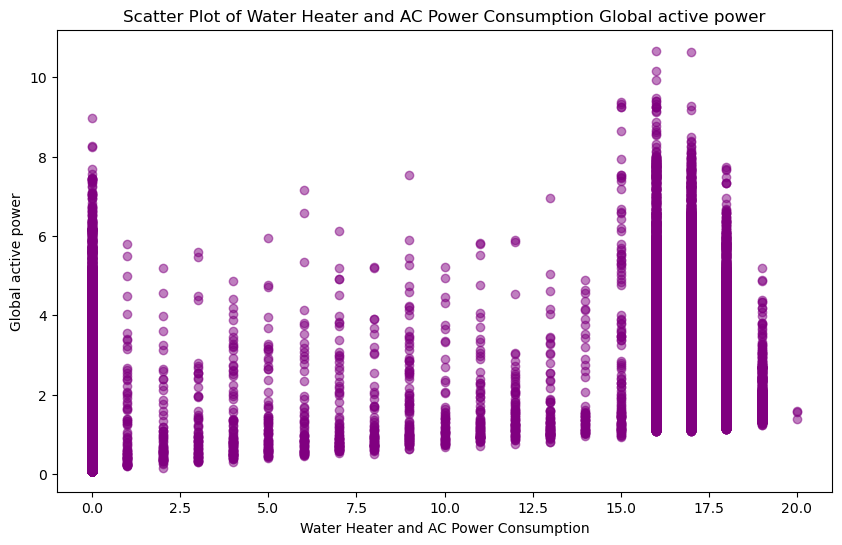

In [22]:
plt.figure(figsize=(10, 6))
plt.scatter(data['Sub_metering_3'], data['Global_active_power'], alpha=0.5, color='purple')
plt.title('Scatter Plot of Water Heater and AC Power Consumption Global active power')
plt.xlabel('Water Heater and AC Power Consumption')
plt.ylabel('Global active power')
plt.show()

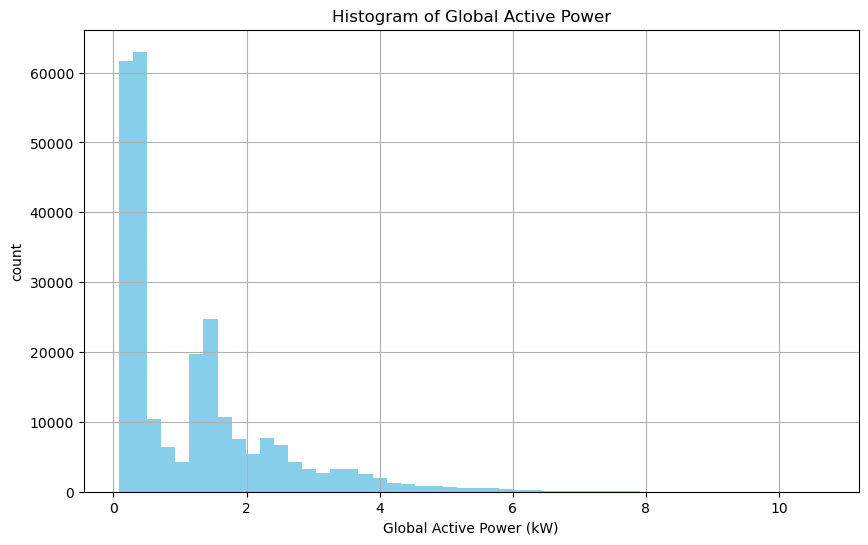

In [23]:
plt.figure(figsize=(10, 6))
data['Global_active_power'].hist(bins=50, color='skyblue')
plt.title('Histogram of Global Active Power')
plt.xlabel('Global Active Power (kW)')
plt.ylabel('count')
plt.show()


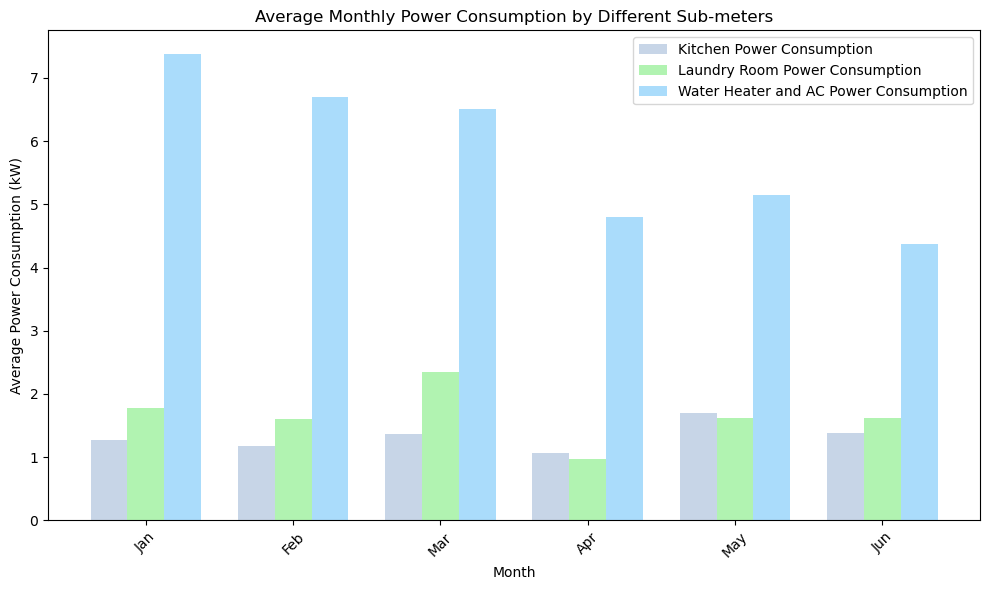

In [24]:
width = 0.25 
monthly_consumption = data.groupby('Month').agg({
    'Sub_metering_1': 'mean',
    'Sub_metering_2': 'mean',
    'Sub_metering_3': 'mean'
}).reset_index()
plt.figure(figsize=(10, 6))

plt.bar(monthly_consumption.index - width, monthly_consumption['Sub_metering_1'], width=width, alpha=0.7, color='lightsteelblue', label='Kitchen Power Consumption')
plt.bar(monthly_consumption.index, monthly_consumption['Sub_metering_2'], width=width, alpha=0.7, color='lightgreen', label='Laundry Room Power Consumption')
plt.bar(monthly_consumption.index + width, monthly_consumption['Sub_metering_3'], width=width, alpha=0.7, color='lightskyblue', label='Water Heater and AC Power Consumption')

plt.xlabel('Month')
plt.ylabel('Average Power Consumption (kW)')
plt.title('Average Monthly Power Consumption by Different Sub-meters')
plt.xticks(ticks=monthly_consumption.index, labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'], rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

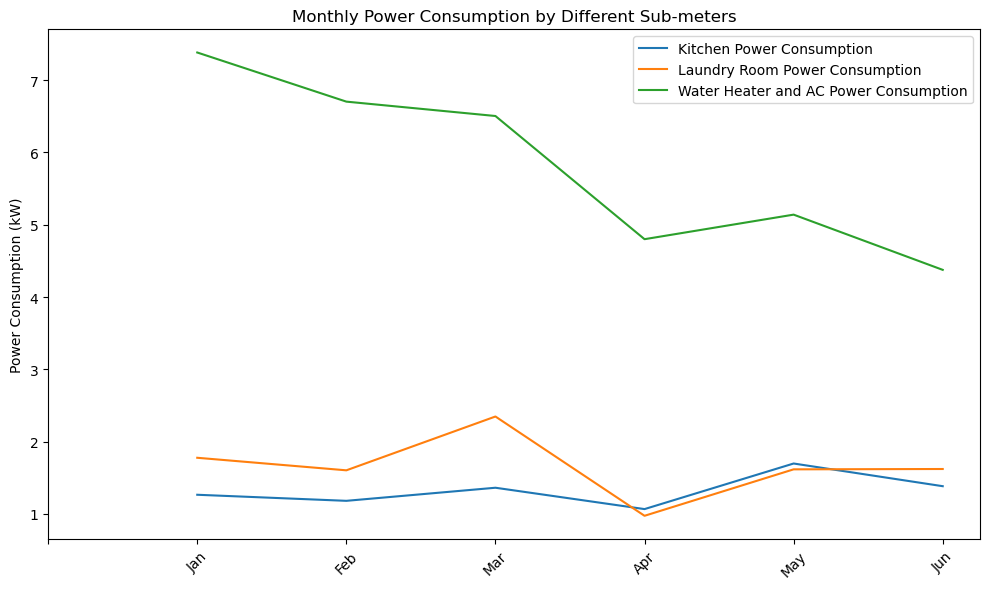

In [25]:
daily_consumption = data.groupby('Month').agg({
    'Sub_metering_1': 'mean',
    'Sub_metering_2': 'mean',
    'Sub_metering_3': 'mean'
}).reset_index()

# ترسیم نمودار
plt.figure(figsize=(10, 6))
plt.plot(daily_consumption['Month'], daily_consumption['Sub_metering_1'], label='Kitchen Power Consumption')
plt.plot(daily_consumption['Month'], daily_consumption['Sub_metering_2'], label='Laundry Room Power Consumption')
plt.plot(daily_consumption['Month'], daily_consumption['Sub_metering_3'], label='Water Heater and AC Power Consumption')

plt.xticks(ticks=range(7), labels=['','Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'], rotation=45)
plt.ylabel('Power Consumption (kW)')
plt.title('Monthly Power Consumption by Different Sub-meters')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

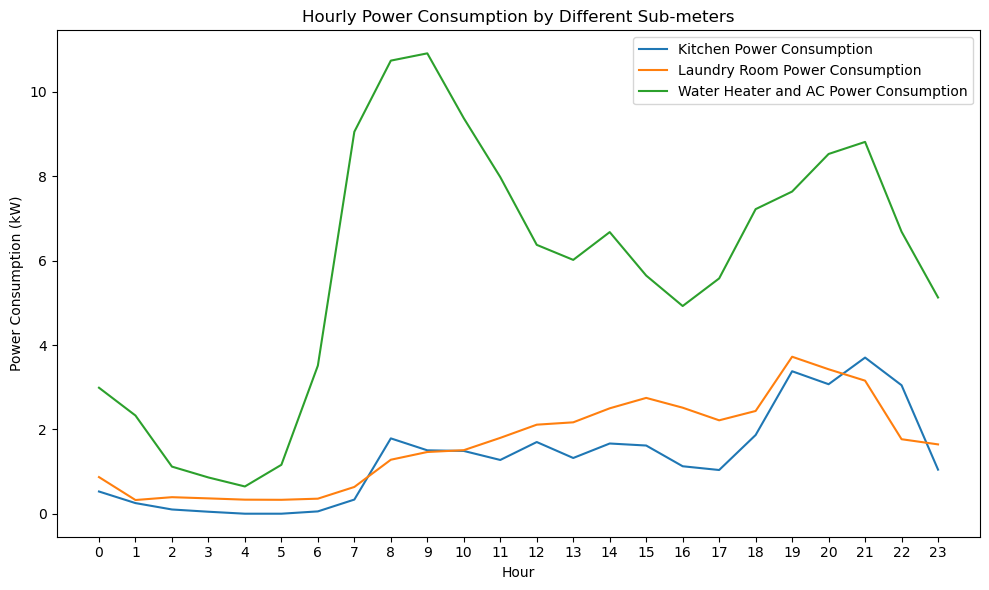

In [26]:
Hourly_consumption = data.groupby('Hour').agg({
    'Sub_metering_1': 'mean',
    'Sub_metering_2': 'mean',
    'Sub_metering_3': 'mean'
}).reset_index()

# ترسیم نمودار
plt.figure(figsize=(10, 6))
plt.plot(Hourly_consumption['Hour'], Hourly_consumption['Sub_metering_1'], label='Kitchen Power Consumption')
plt.plot(Hourly_consumption['Hour'], Hourly_consumption['Sub_metering_2'], label='Laundry Room Power Consumption')
plt.plot(Hourly_consumption['Hour'], Hourly_consumption['Sub_metering_3'], label='Water Heater and AC Power Consumption')

plt.xlabel('Hour')
plt.ylabel('Power Consumption (kW)')
plt.title('Hourly Power Consumption by Different Sub-meters')
plt.legend()
plt.xticks(ticks=range(0,24))
plt.tight_layout()
plt.show()

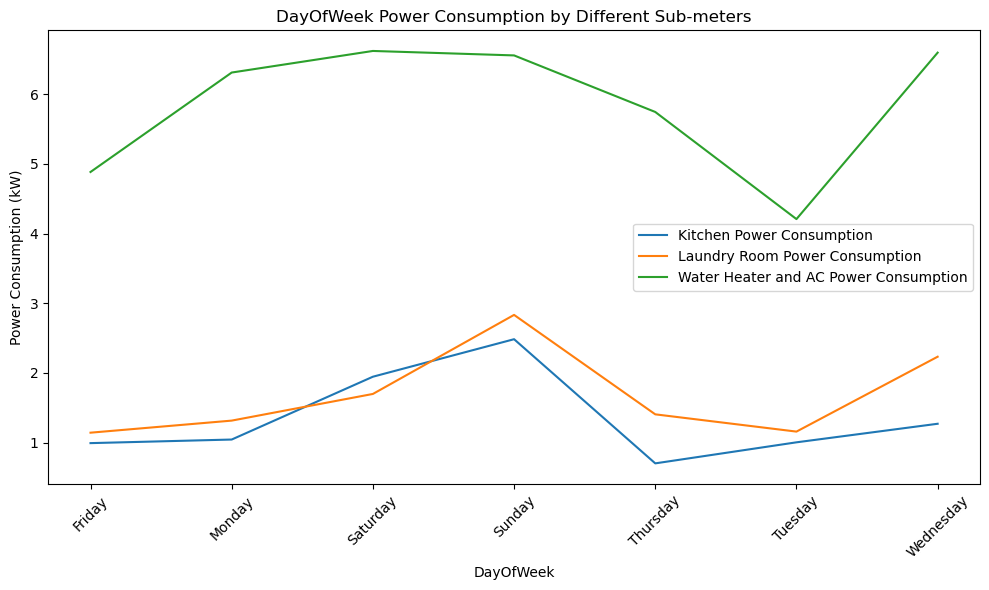

In [27]:
Hourly_consumption = data.groupby('DayOfWeek').agg({
    'Sub_metering_1': 'mean',
    'Sub_metering_2': 'mean',
    'Sub_metering_3': 'mean'
}).reset_index()

# ترسیم نمودار
plt.figure(figsize=(10, 6))
plt.plot(Hourly_consumption['DayOfWeek'], Hourly_consumption['Sub_metering_1'], label='Kitchen Power Consumption')
plt.plot(Hourly_consumption['DayOfWeek'], Hourly_consumption['Sub_metering_2'], label='Laundry Room Power Consumption')
plt.plot(Hourly_consumption['DayOfWeek'], Hourly_consumption['Sub_metering_3'], label='Water Heater and AC Power Consumption')

plt.xlabel('DayOfWeek')
plt.ylabel('Power Consumption (kW)')
plt.title('DayOfWeek Power Consumption by Different Sub-meters')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

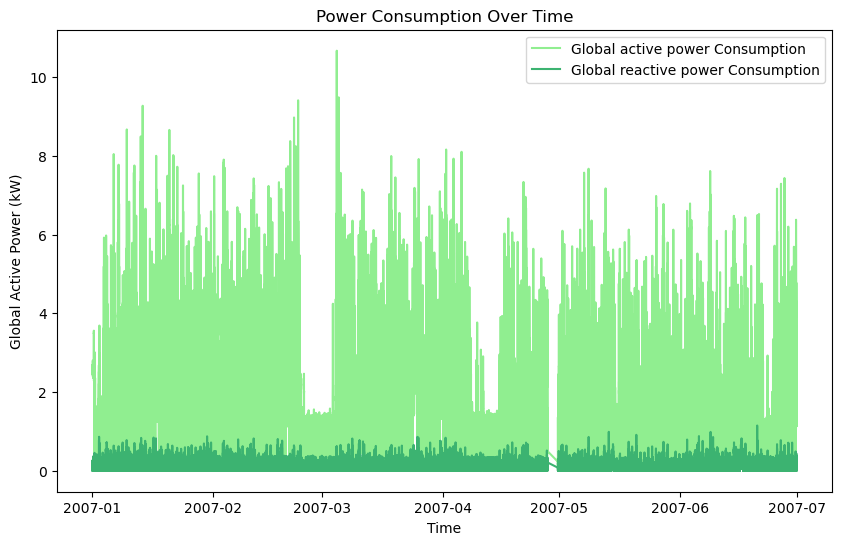

In [28]:
plt.figure(figsize=(10, 6))
plt.plot(data['Datetime'],data['Global_active_power'],color='lightgreen',label='Global active power Consumption')
plt.plot(data['Datetime'],data['Global_reactive_power'],color='mediumseagreen',label='Global reactive power Consumption')
plt.title('Power Consumption Over Time')
plt.xlabel('Time')
plt.legend()
plt.ylabel('Global Active Power (kW)')
plt.show()


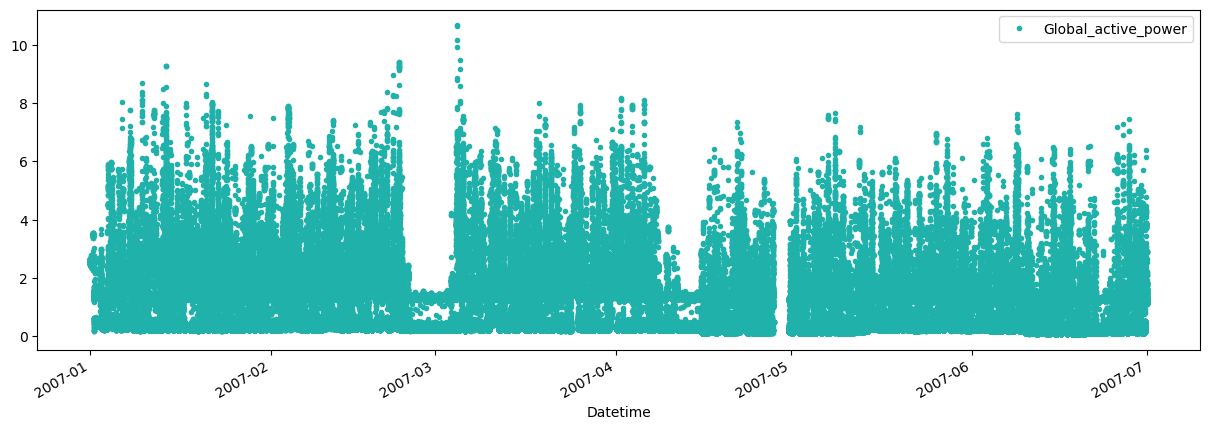

In [29]:
data.plot(x='Datetime', y='Global_active_power',style='.',
        figsize=(15, 5)
         ,color='lightseagreen')
plt.show()

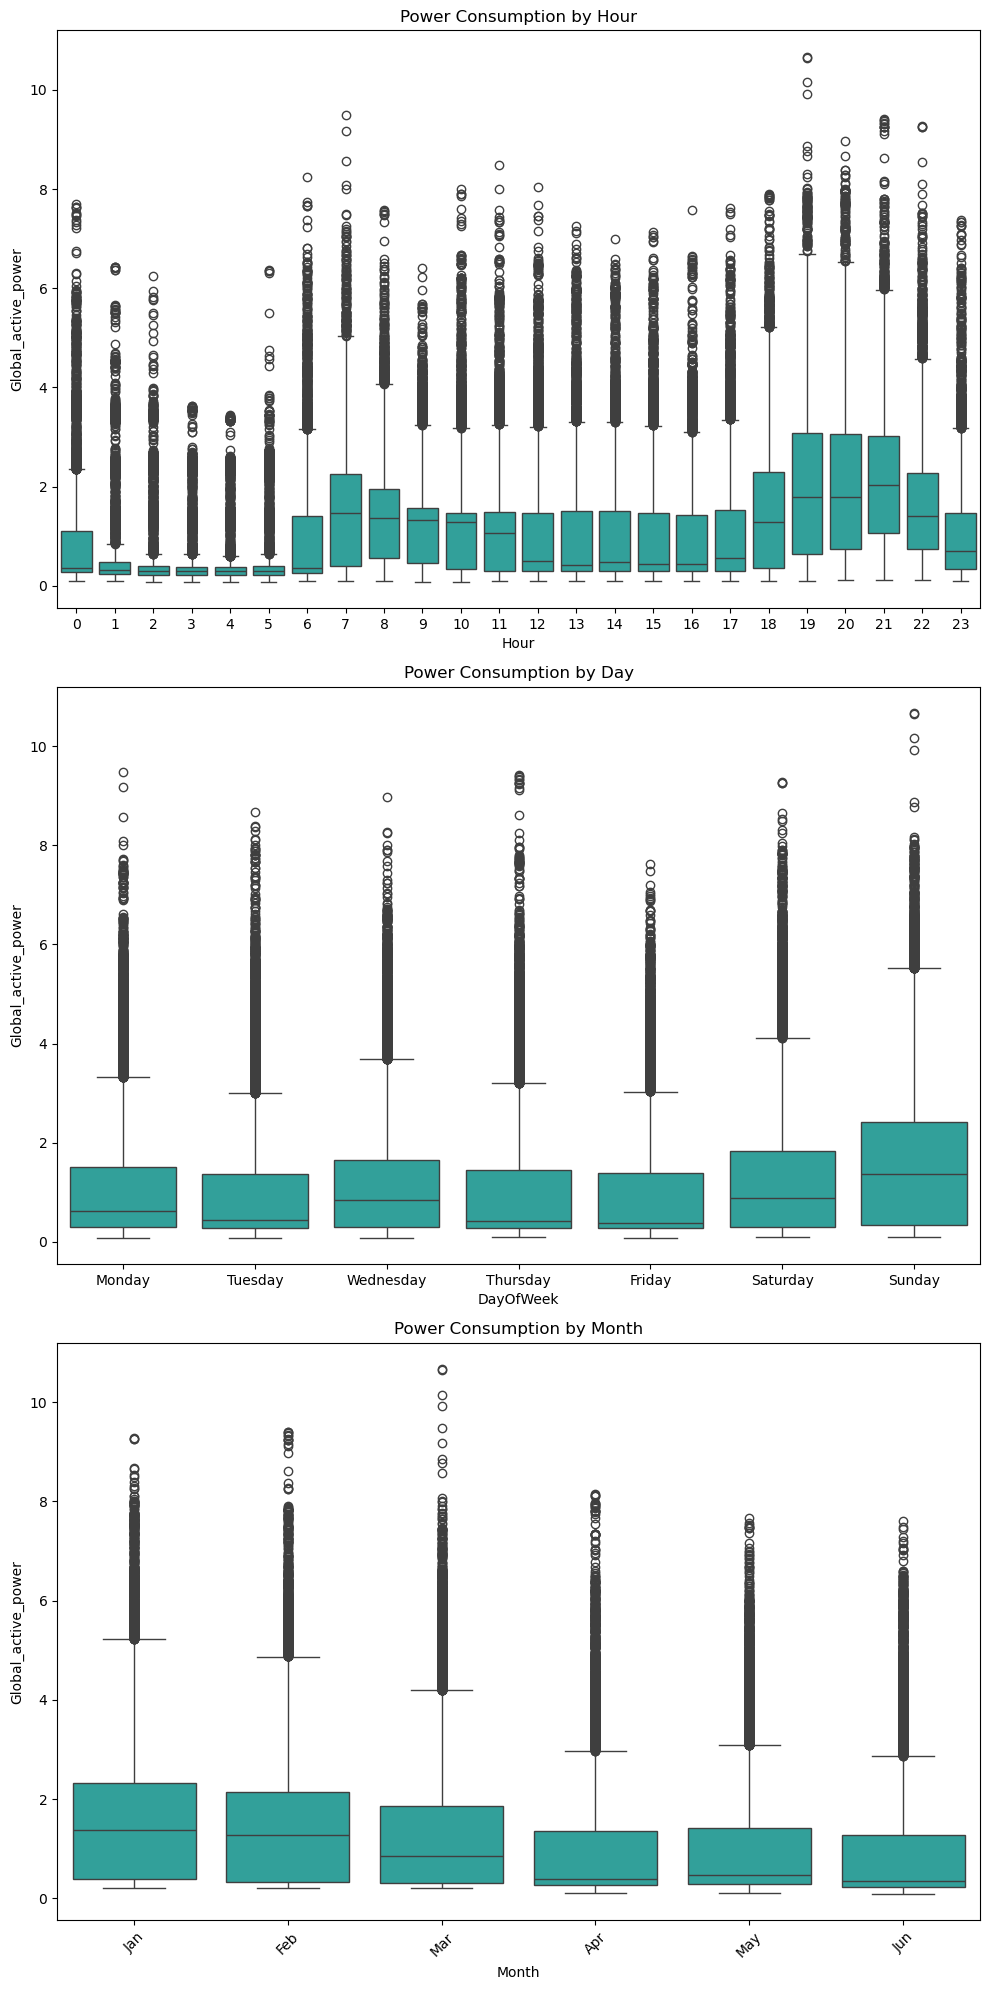

In [30]:

fig, axs = plt.subplots(3, 1, figsize=(10, 20))

# Consumption by Hour
sns.boxplot(data=data, x='Hour', y='Global_active_power', ax=axs[0], color='lightseagreen')
axs[0].set_title('Power Consumption by Hour')

# Consumption by Day
sns.boxplot(data=data, x='DayOfWeek', y='Global_active_power', ax=axs[1], color='lightseagreen')
axs[1].set_title('Power Consumption by Day')

# Consumption by Month
sns.boxplot(data=data, x='Month', y='Global_active_power', ax=axs[2], color='lightseagreen')
axs[2].set_title('Power Consumption by Month')
plt.xticks(ticks=range(6), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'], rotation=45)




plt.tight_layout()
plt.show()

In [31]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# Select the feature to be one-hot encoded
X = data[['DayOfWeek']]  # 'DayOfWeek' feature

# Create the OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)  # sparse_output=False returns a dense array

# Fit and transform the 'DayOfWeek' feature
encoded_dayofweek = encoder.fit_transform(X)

# Create a DataFrame with the one-hot encoded columns
encoded_columns = encoder.get_feature_names_out(['DayOfWeek'])
encoded_df = pd.DataFrame(encoded_dayofweek, columns=encoded_columns)

# Show the result
encoded_df



,DayOfWeek_Friday,DayOfWeek_Monday,DayOfWeek_Saturday,DayOfWeek_Sunday,DayOfWeek_Thursday,DayOfWeek_Tuesday,DayOfWeek_Wednesday
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...
256864,0.0,0.0,1.0,0.0,0.0,0.0,0.0
256865,0.0,0.0,1.0,0.0,0.0,0.0,0.0
256866,0.0,0.0,1.0,0.0,0.0,0.0,0.0
256867,0.0,0.0,1.0,0.0,0.0,0.0,0.0


Linear Regression

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Feature selection
X = data[['Hour', 'DayOfWeek', 'Month']]  # Features
y = data['Global_active_power']  # Target variable

X_encoded = X.drop(columns=['DayOfWeek'])
X_encoded = pd.concat([X_encoded, encoded_df], axis=1)
X_encoded = X_encoded.drop(columns=['Hour'])
X_encoded = pd.concat([X_encoded, encoded_df], axis=1)
X_encoded = X_encoded.drop(columns=['Month'])
X_encoded = pd.concat([X_encoded, encoded_df], axis=1)
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Create and train the Linear Regression model
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# Make predictions
y_pred_lr = model_lr.predict(X_test)

# Evaluate the model
mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Print the results
print(f'MSE (Linear Regression): {mse_lr}')
print(f'R² (Linear Regression): {r2_lr}')


MSE (Linear Regression): 1.339016176840927
R² (Linear Regression): 0.03177132569579699


Decision Tree

In [33]:
from sklearn.tree import DecisionTreeRegressor

# Create the Decision Tree model
model_dt = DecisionTreeRegressor(random_state=42)

# Train the model
model_dt.fit(X_train, y_train)

# Make predictions
y_pred_dt = model_dt.predict(X_test)

# Evaluate the model
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

# Print the results
print(f'MSE (Decision Tree): {mse_dt}')
print(f'R² (Decision Tree): {r2_dt}')


MSE (Decision Tree): 1.339016176840928
R² (Decision Tree): 0.031771325695796215


Random Forest

In [34]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
model_rf = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the model
model_rf.fit(X_train, y_train)

# Make predictions
y_pred_rf = model_rf.predict(X_test)

# Evaluate the model
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# Print the results
print(f'MSE (Random Forest): {mse_rf}')
print(f'R² (Random Forest): {r2_rf}')


MSE (Random Forest): 1.33900613116445
R² (Random Forest): 0.03177858962000202


MLP - Multi-layer Perceptron

In [35]:
from sklearn.neural_network import MLPRegressor

# Create the MLP model (Multi-layer Perceptron)
model_mlp = MLPRegressor(hidden_layer_sizes=(50,), max_iter=1000, random_state=42)

# Train the model
model_mlp.fit(X_train, y_train)

# Make predictions
y_pred_mlp = model_mlp.predict(X_test)

# Evaluate the model
mse_mlp = mean_squared_error(y_test, y_pred_mlp)
r2_mlp = r2_score(y_test, y_pred_mlp)

# Print the results
print(f'MSE (MLP): {mse_mlp}')
print(f'R² (MLP): {r2_mlp}')


MSE (MLP): 1.3390512850868312
R² (MLP): 0.03174593928824132


In [36]:
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt

# تنظیم 'Datetime' به عنوان ایندکس
data.set_index('Datetime', inplace=True)

# انتخاب داده‌های مصرف برق برای پیش‌بینی
data_consumption = data['Global_active_power']

/opt/miniconda3/envs/my-project/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/miniconda3/envs/my-project/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/miniconda3/envs/my-project/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/miniconda3/envs/my-project/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an

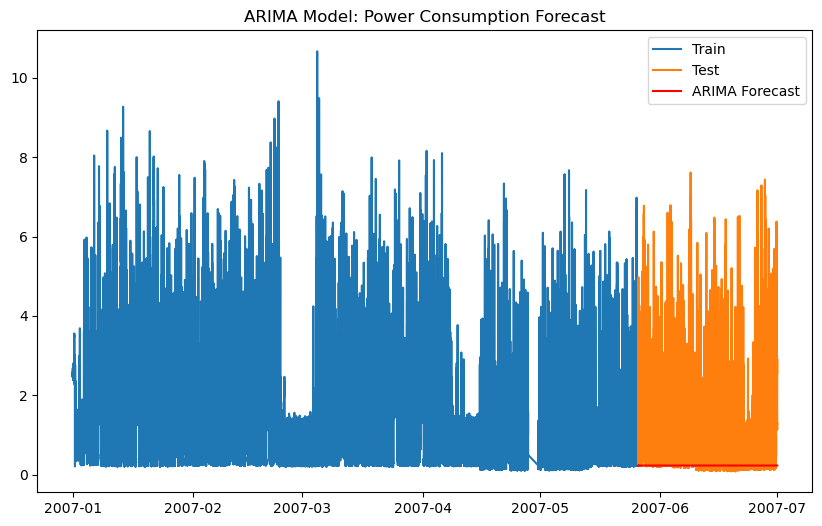

In [37]:
# تقسیم داده‌ها به داده‌های آموزشی و تست
train_size = int(len(data_consumption) * 0.8)
train, test = data_consumption[:train_size], data_consumption[train_size:]

# ایجاد مدل ARIMA (مقادیر p, d, q باید از قبل انتخاب شوند)
model_arima = ARIMA(train, order=(5, 1, 0))  # (p, d, q)
model_arima_fit = model_arima.fit()

# پیش‌بینی مصرف برق
forecast_arima = model_arima_fit.forecast(steps=len(test))

# ارزیابی مدل
plt.figure(figsize=(10, 6))
plt.plot(train, label='Train')
plt.plot(test, label='Test')
plt.plot(test.index, forecast_arima, label='ARIMA Forecast', color='red')
plt.legend()
plt.title('ARIMA Model: Power Consumption Forecast')
plt.show()


In [38]:
import scipy.stats as stats
import pylab
#function to return plots for the feature
def norm_plot(data,feature):
    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    sns.kdeplot(data[feature])
    plt.subplot(1,2,2)
    stats.probplot(data[feature],plot=pylab)
    plt.show()

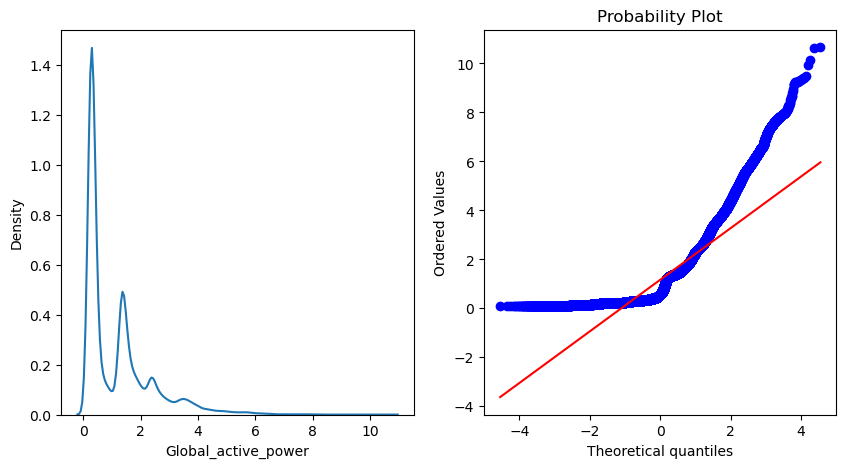

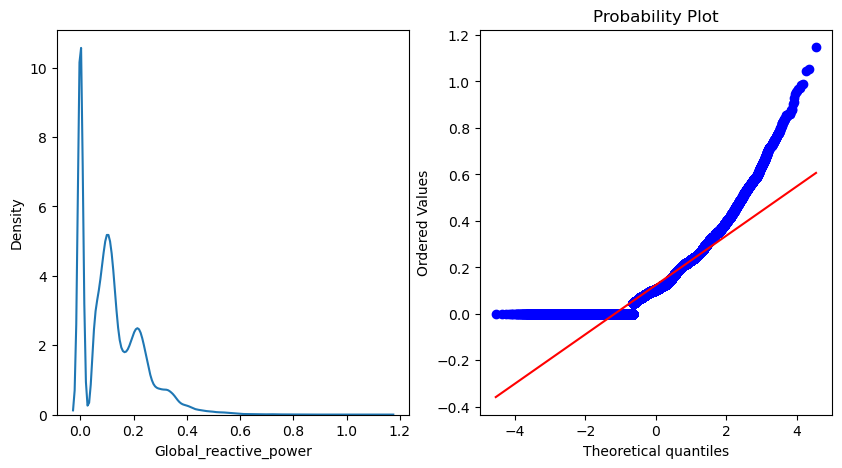

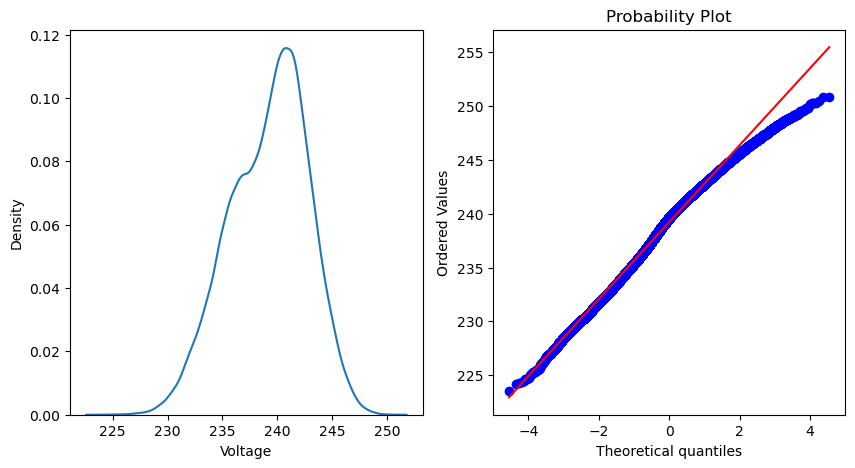

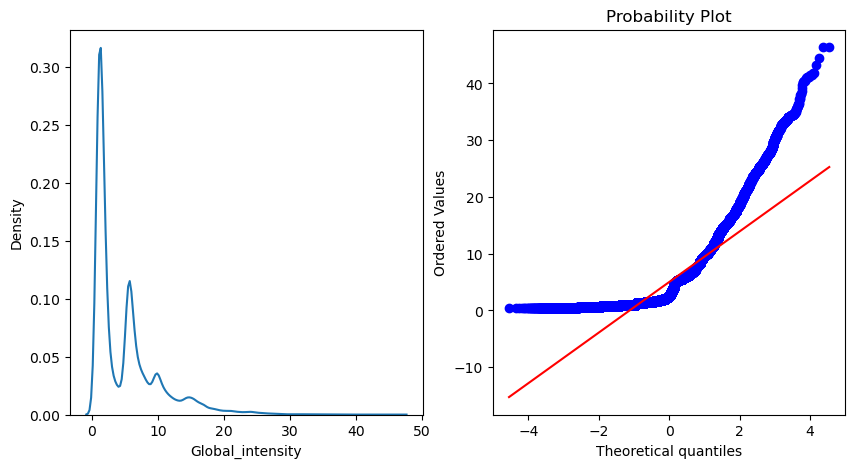

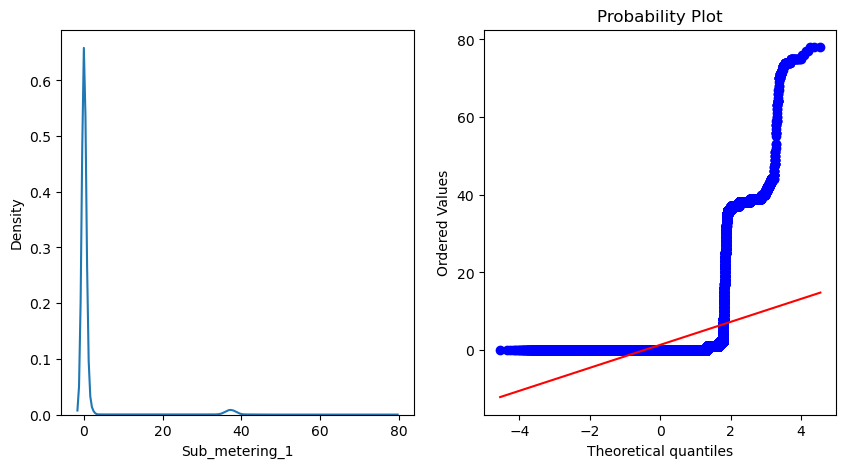

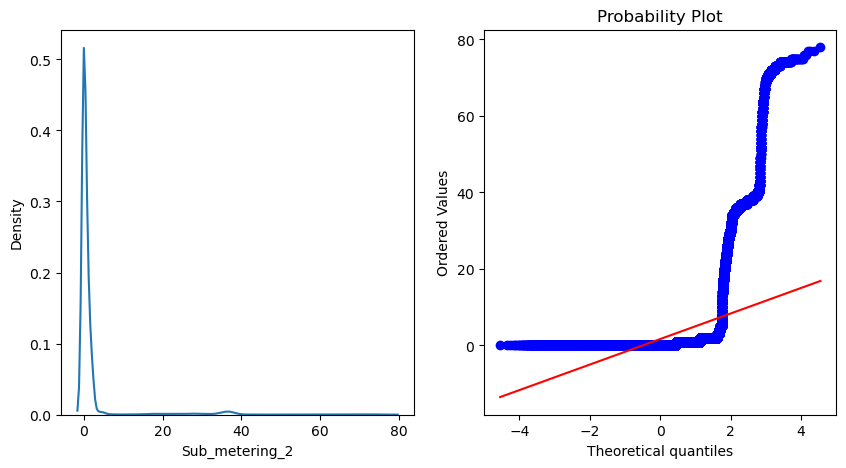

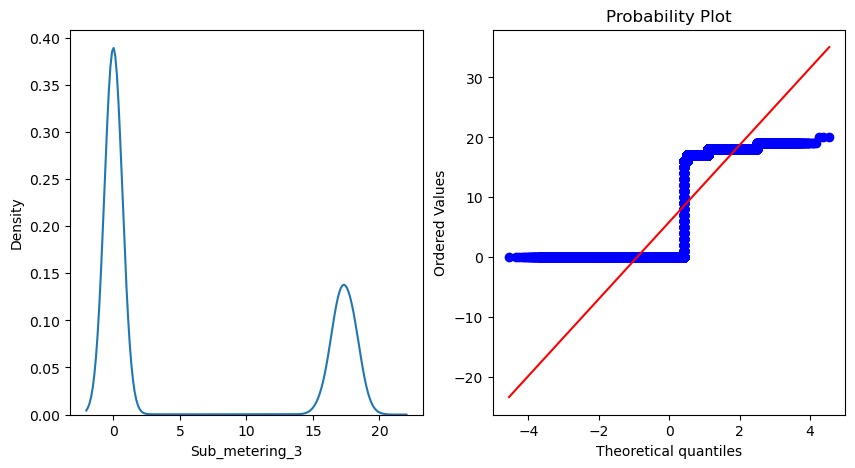

In [39]:
float_cols = ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
for x in float_cols:
    norm_plot(data,feature=x)

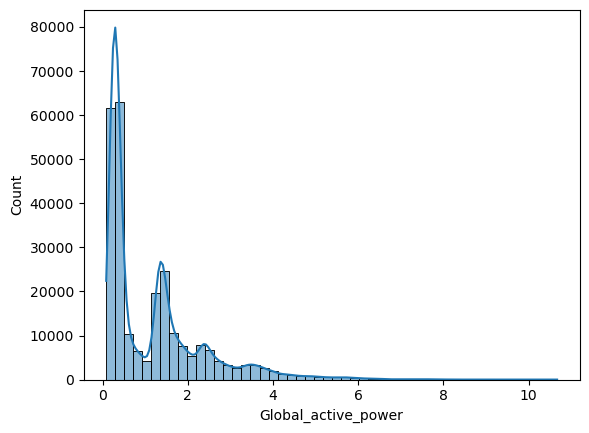

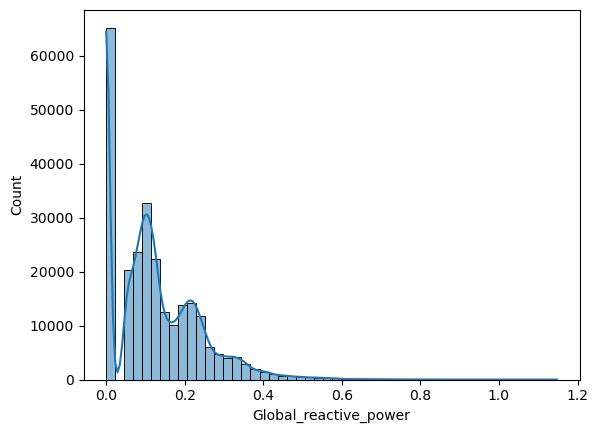

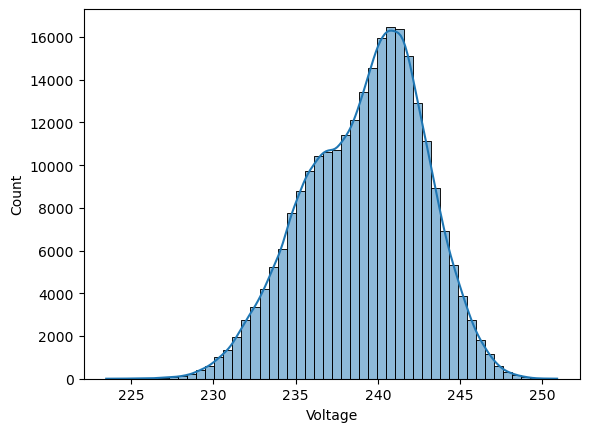

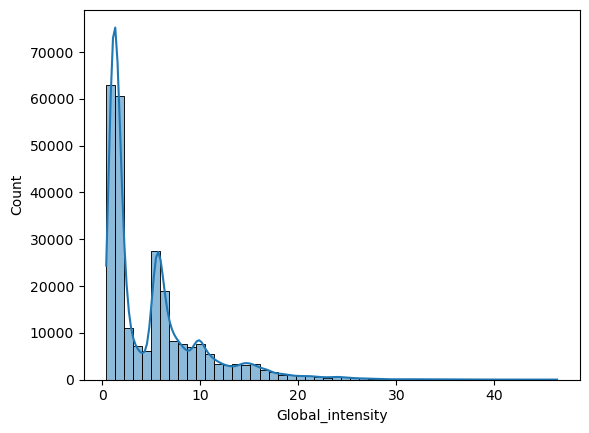

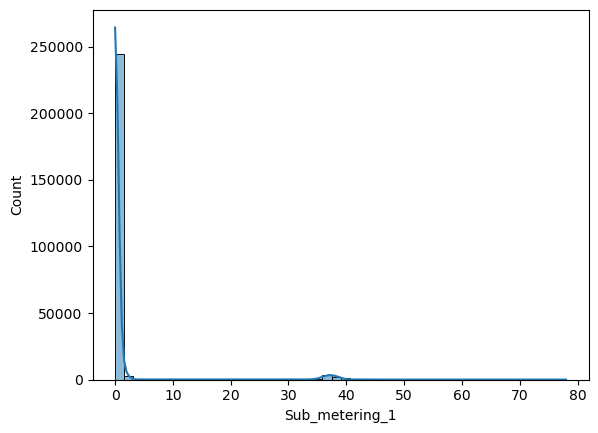

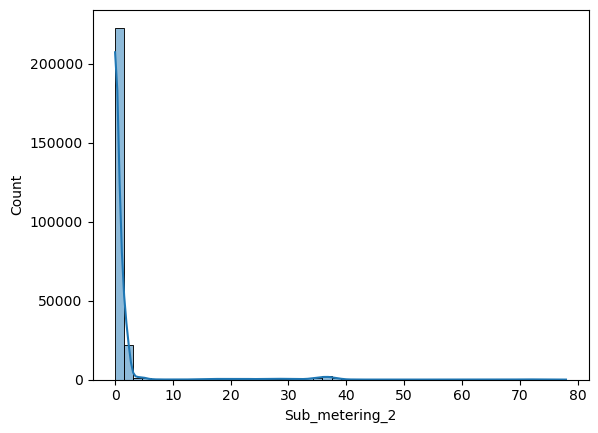

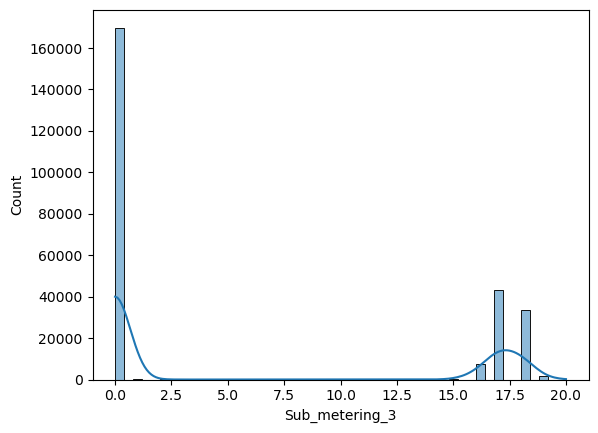

In [40]:
model_var =['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


for x in model_var:
    sns.histplot(
        data=data[x],
        bins=50,
        kde=True
    )
    plt.show()

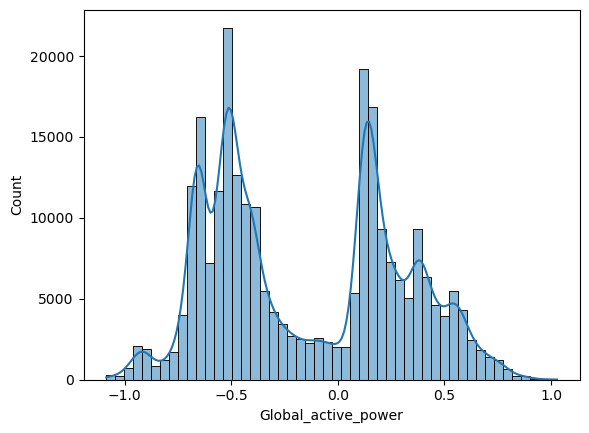

/opt/miniconda3/envs/my-project/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


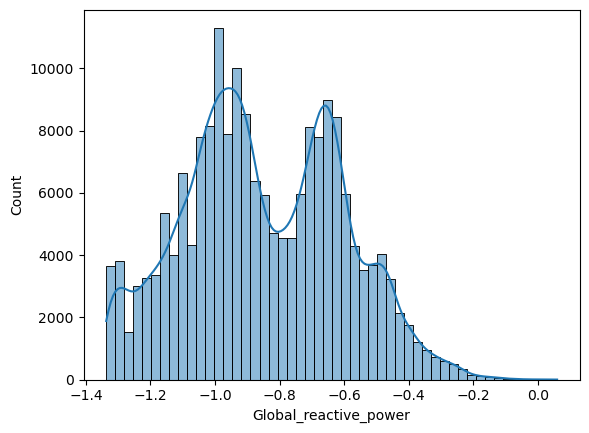

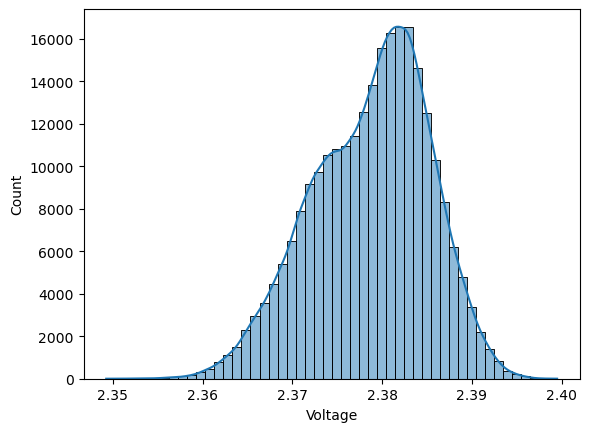

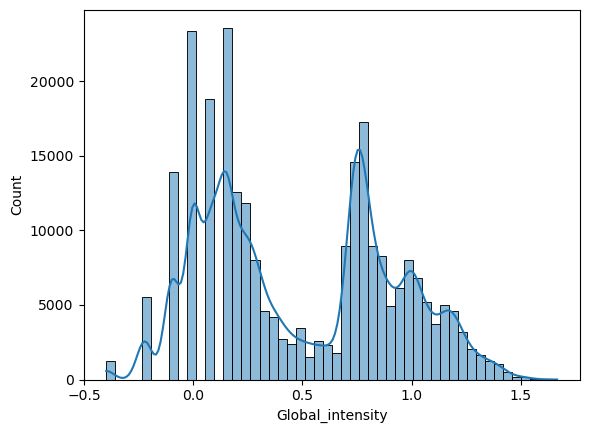

/opt/miniconda3/envs/my-project/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


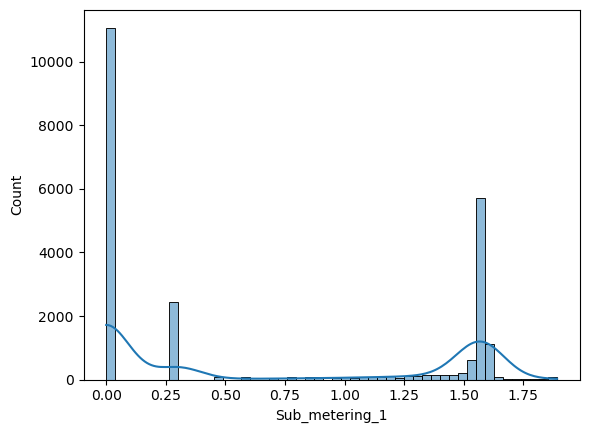

/opt/miniconda3/envs/my-project/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


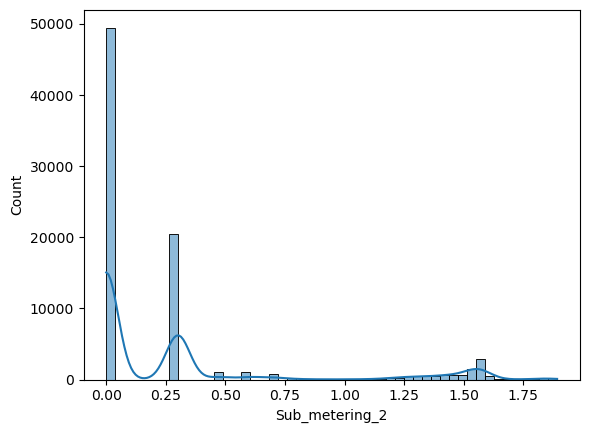

/opt/miniconda3/envs/my-project/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


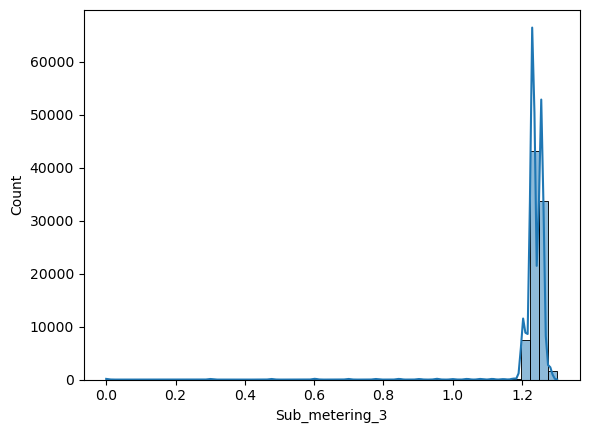

In [41]:
model_var =['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


for x in model_var:
    sns.histplot(
        data=np.log10(data[x]),
        bins=50,
        kde=True
    )
    plt.show()

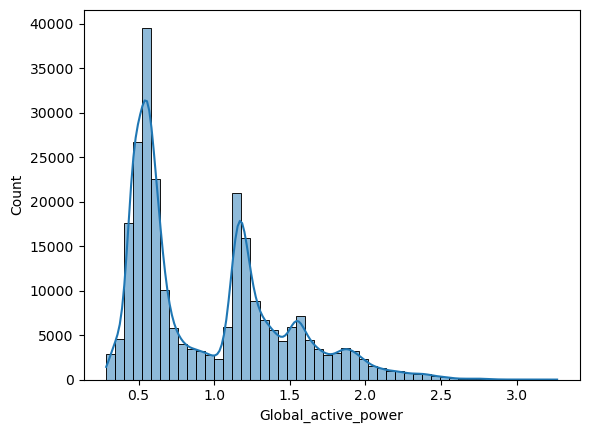

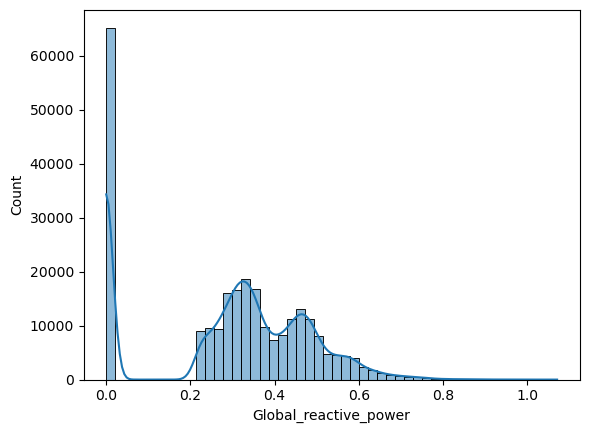

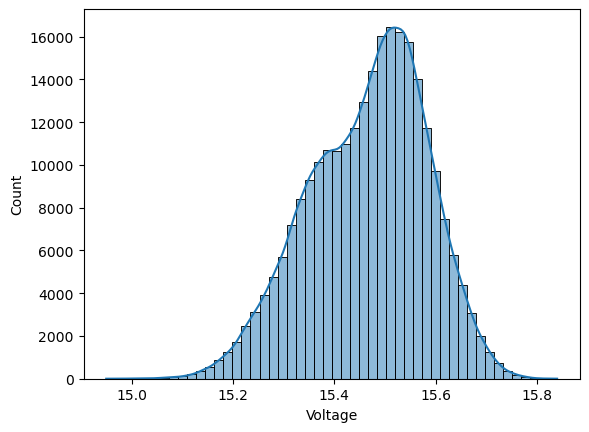

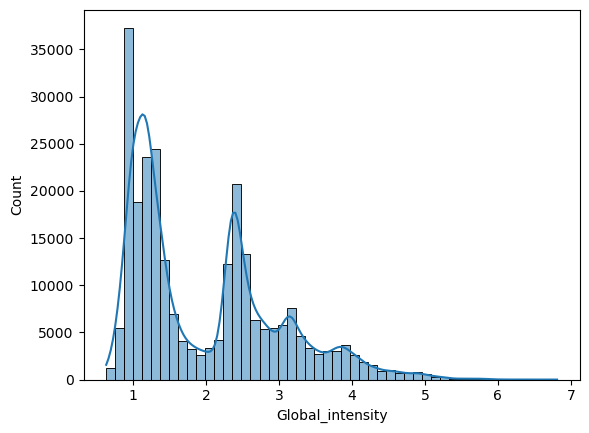

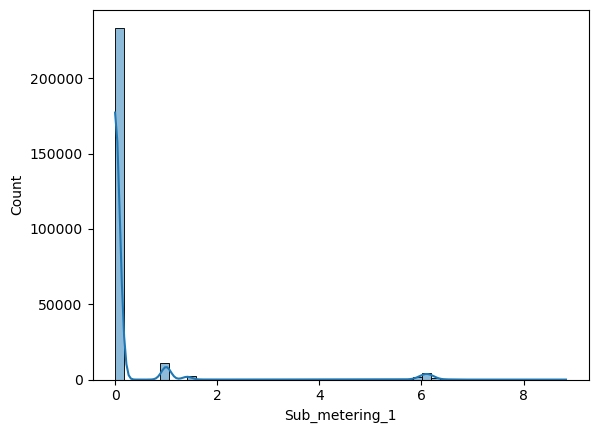

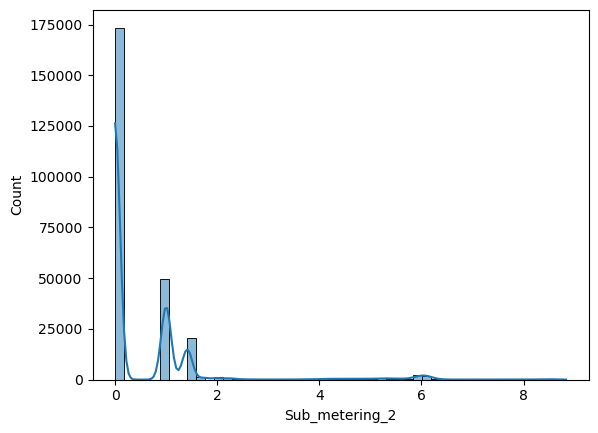

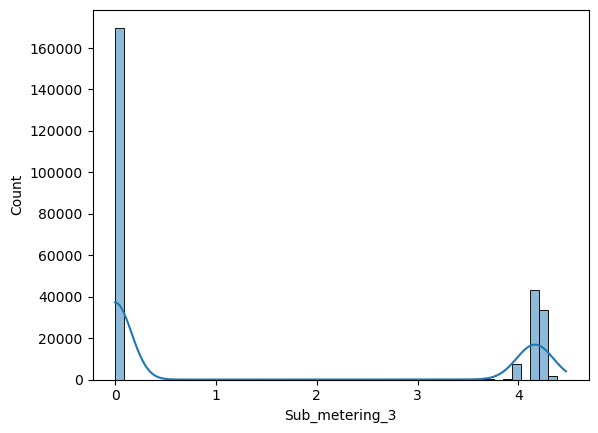

In [42]:
for x in model_var:
    sns.histplot(
        data=np.sqrt(data[x]),
        bins=50,
        kde=True
    )
    plt.show()

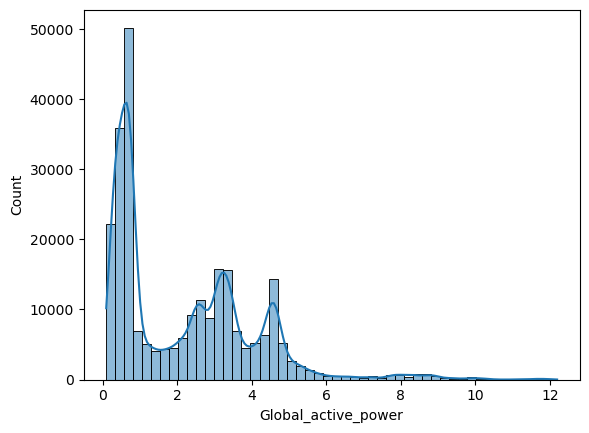

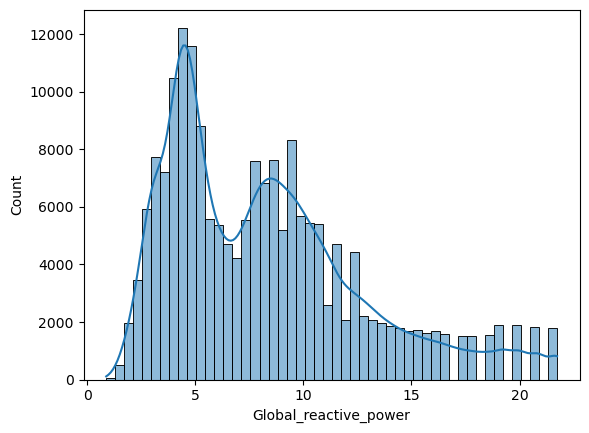

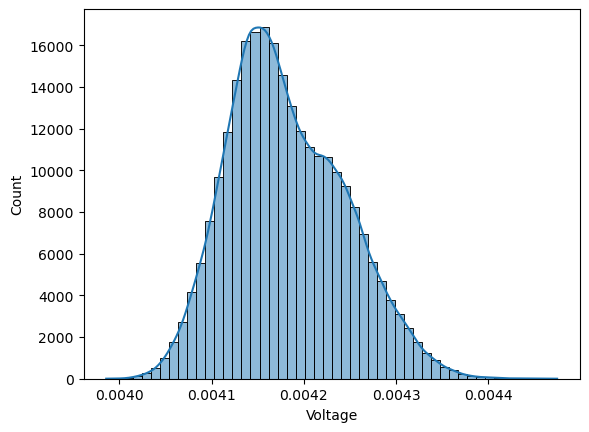

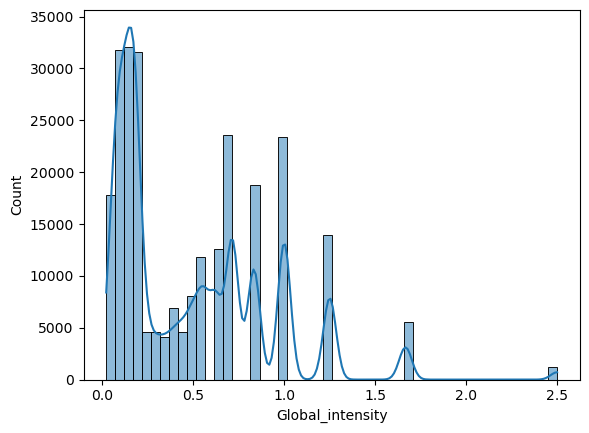

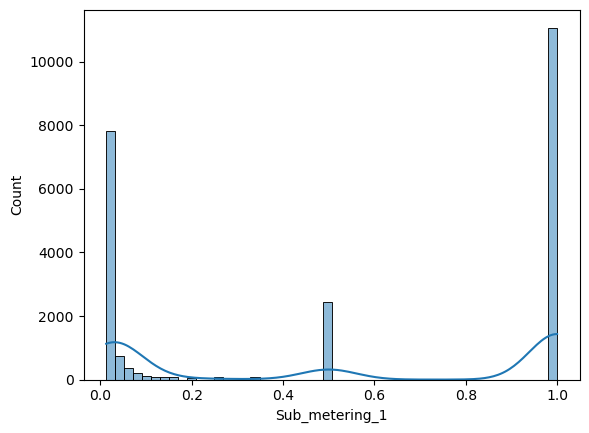

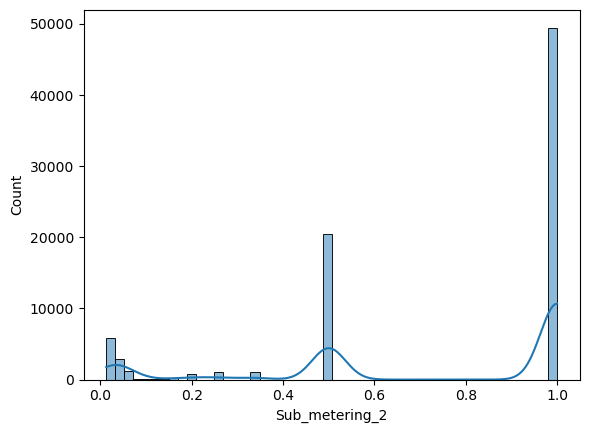

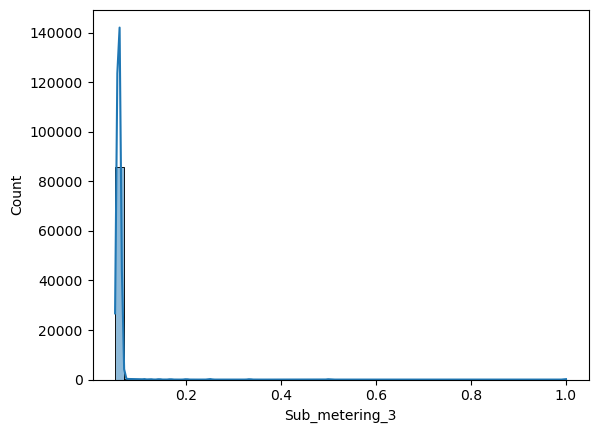

In [43]:
for x in model_var:
    sns.histplot(
        data=1/data[x],
        bins=50,
        kde=True
    )
    plt.show()

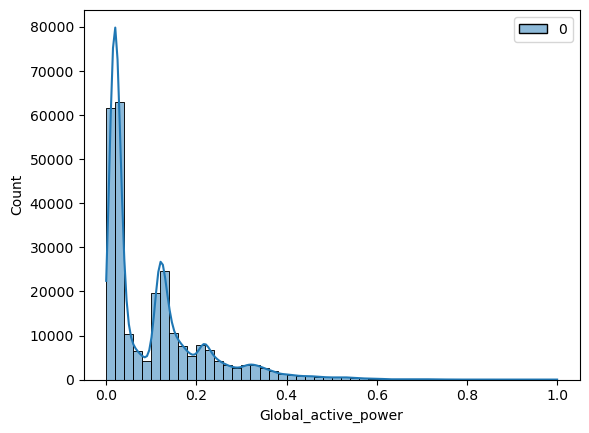

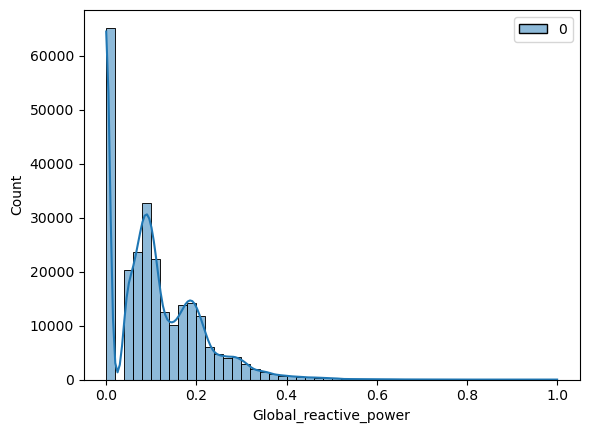

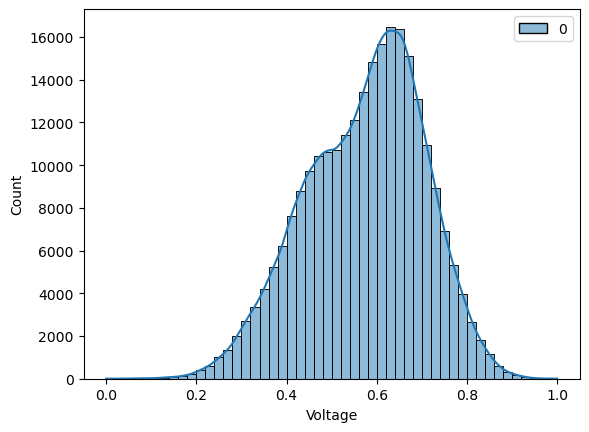

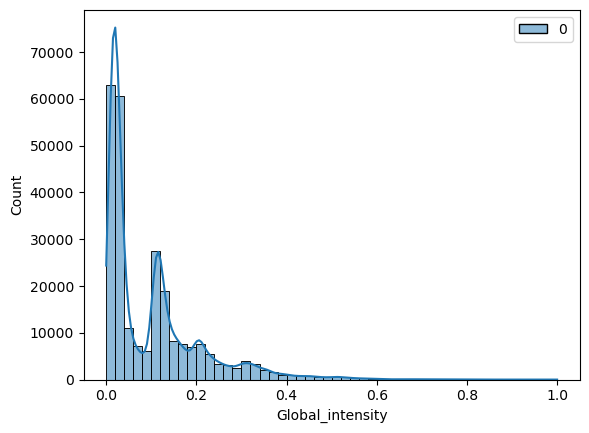

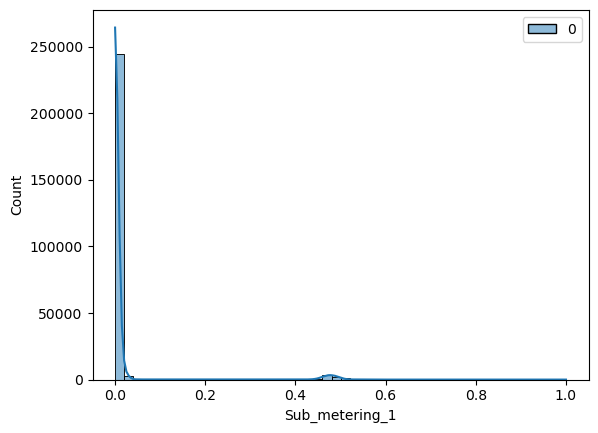

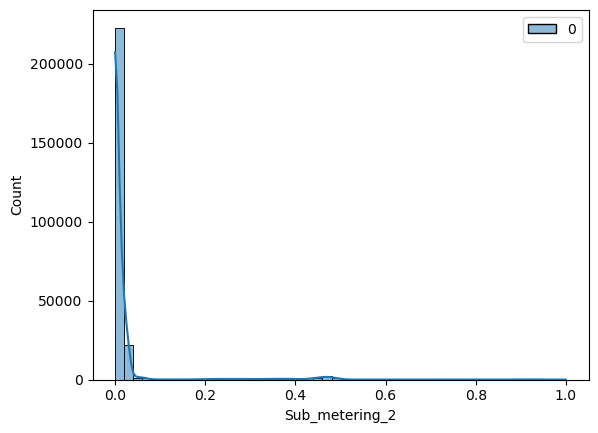

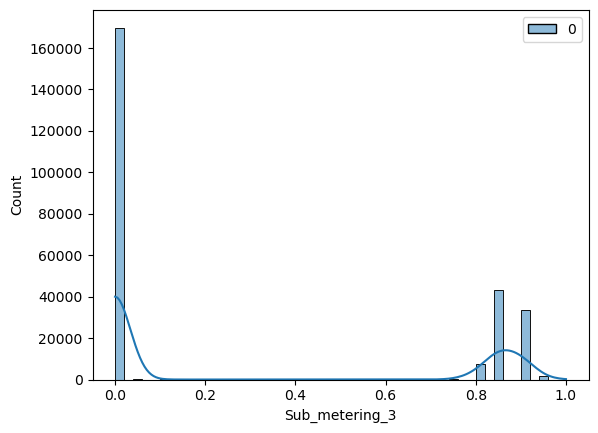

In [44]:
model_var = ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
scaler = MinMaxScaler()

for x in model_var:
    # Reshape the data to 2D for scaling
    data_scaled = scaler.fit_transform(data[[x]])  # Use double brackets to select a single column as DataFrame
    sns.histplot(data_scaled, bins=50, kde=True)
    plt.xlabel(x)
    plt.show()

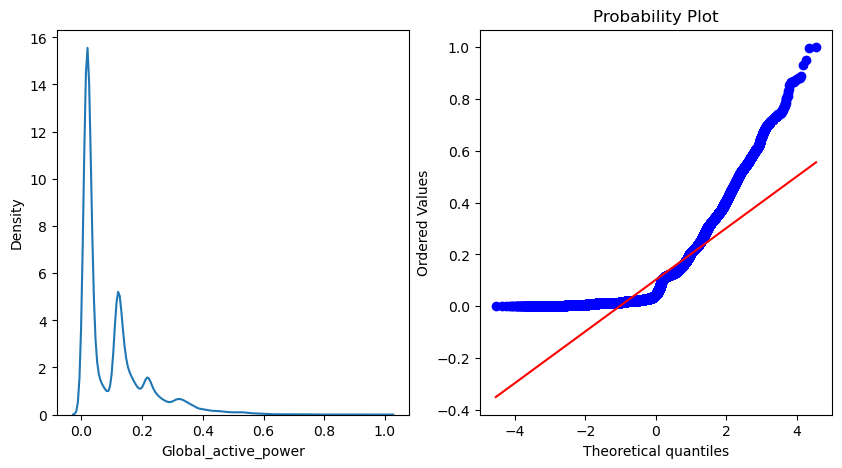

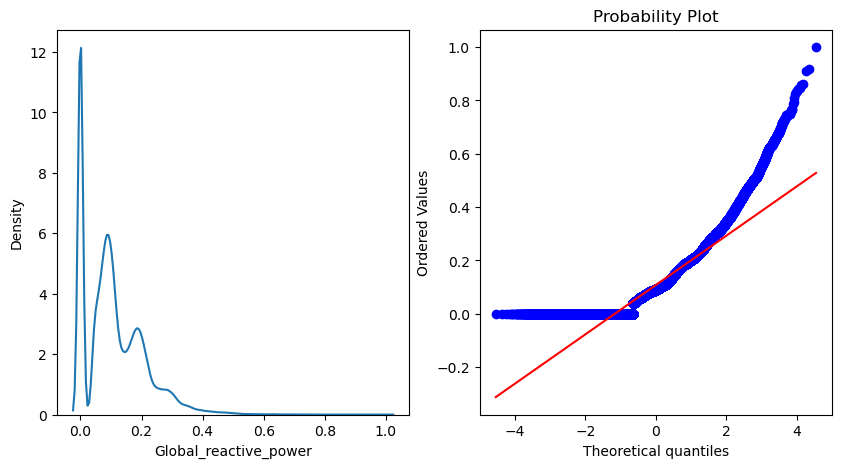

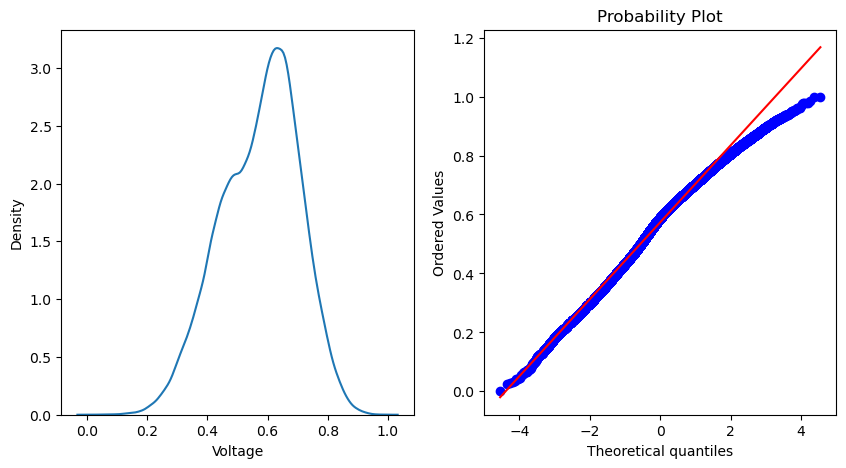

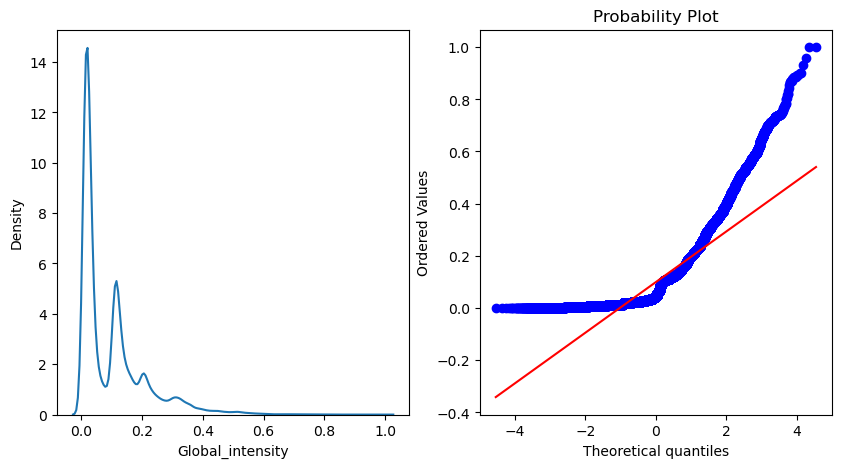

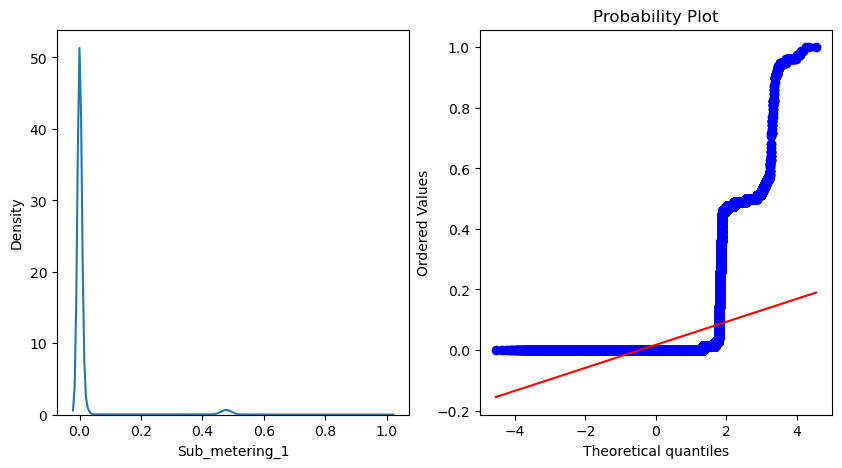

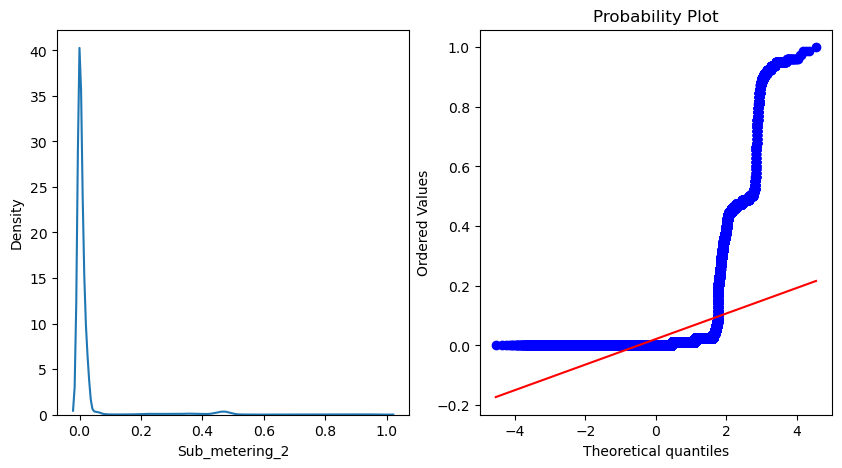

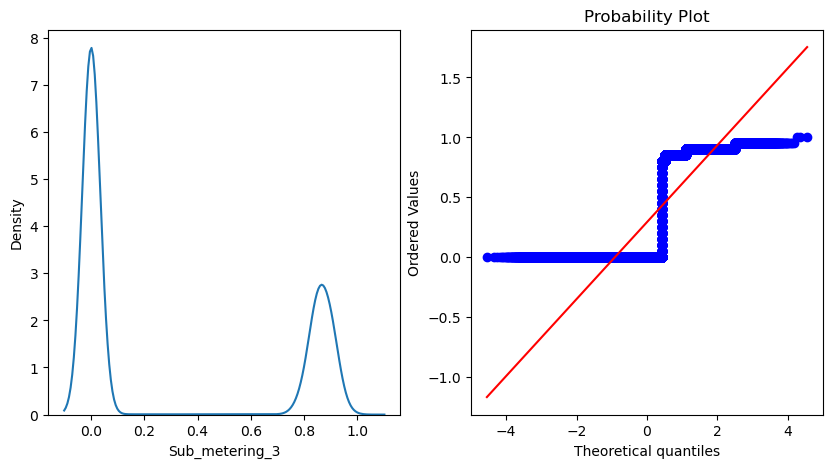

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler



float_cols = ['Global_active_power', 'Global_reactive_power', 'Voltage', 
              'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

# تعریف تابع نرمال‌سازی و رسم نمودار
def norm_plot(data, feature):
    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    sns.kdeplot(data[feature])
    plt.subplot(1,2,2)
    stats.probplot(data[feature], plot=pylab)
    plt.show()

# نرمال‌سازی با MinMaxScaler و بررسی نرمال بودن
scaler = MinMaxScaler()

for col in float_cols:
    # نرمال‌سازی با MinMaxScaler
    data[col] = scaler.fit_transform(data[[col]])
    
    # بررسی نرمال بودن بعد از تغییر
    norm_plot(data, col)


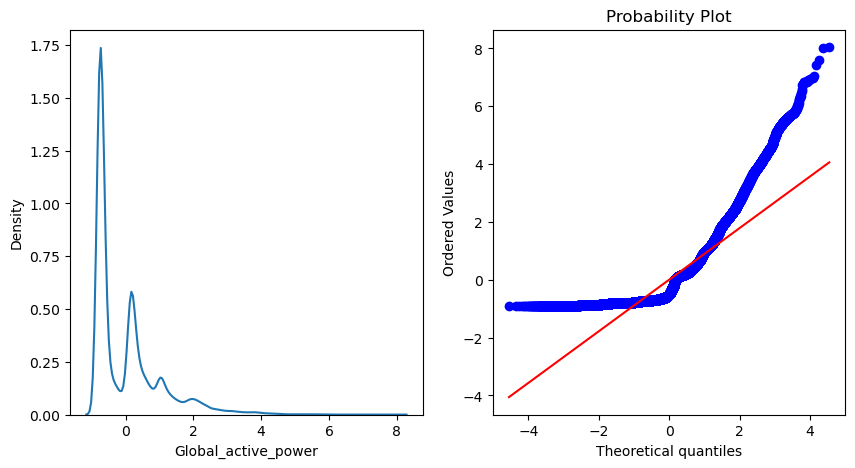

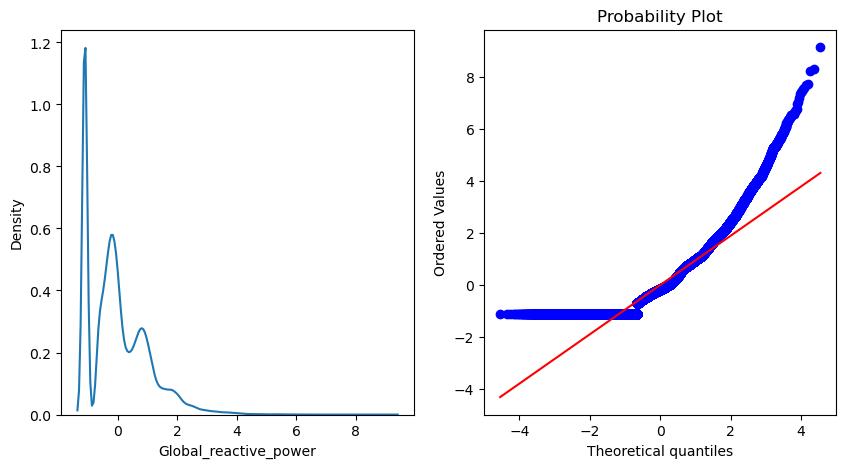

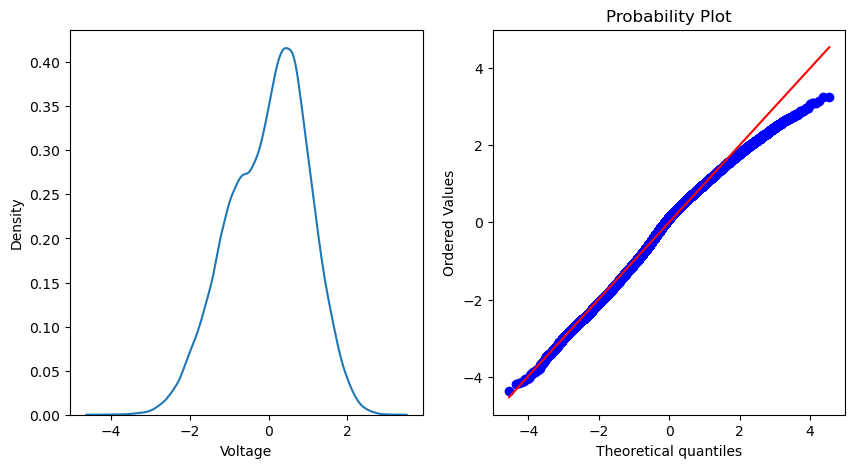

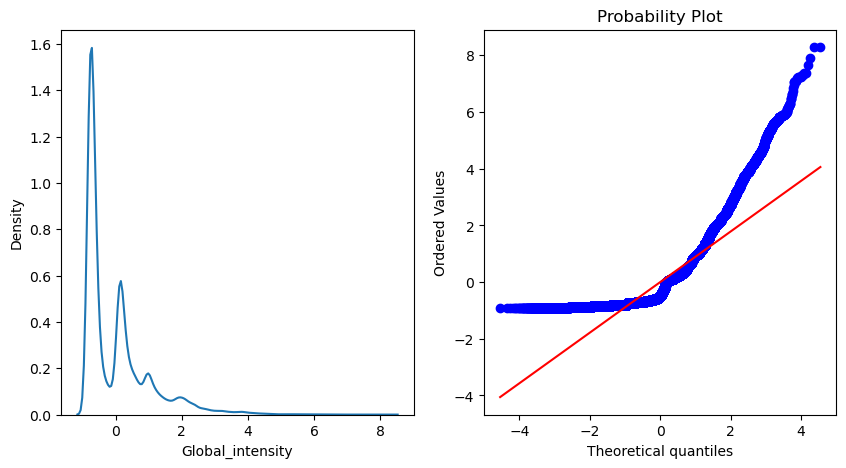

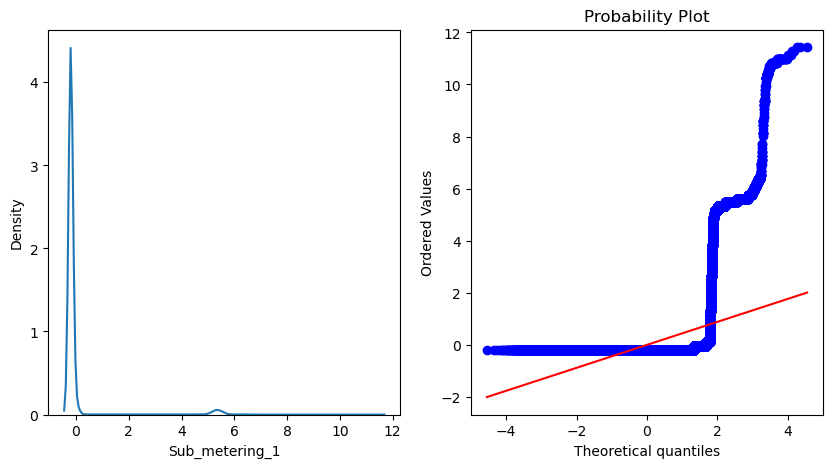

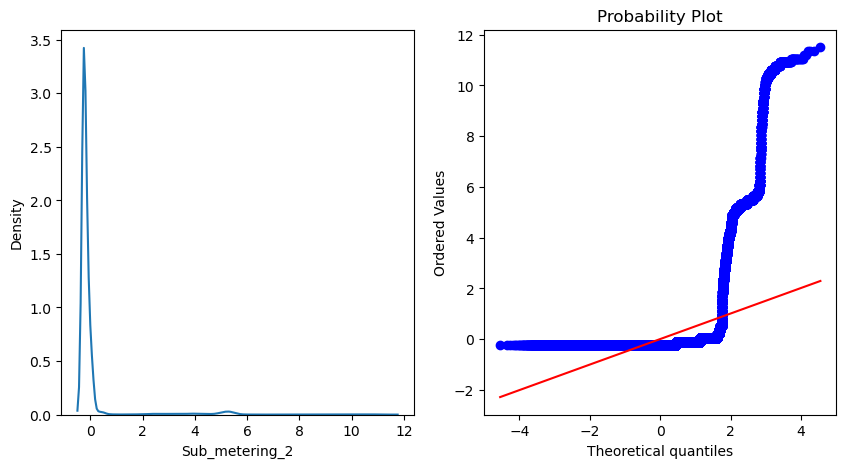

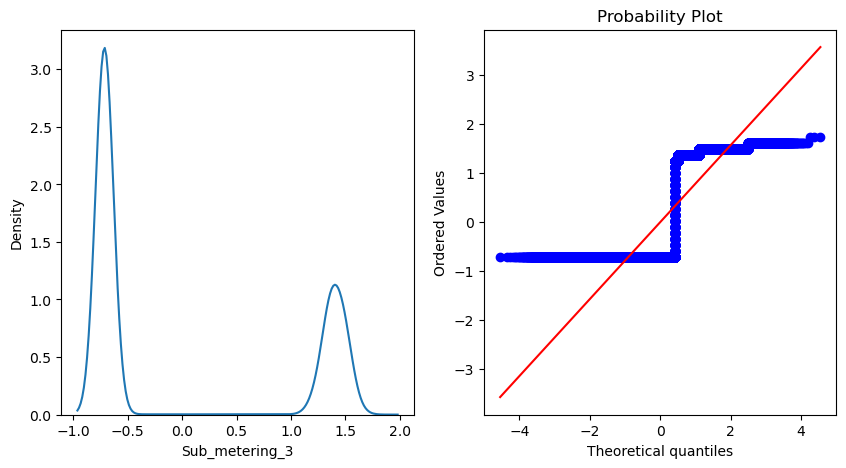

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy import stats

# ویژگی‌های عددی
float_cols = ['Global_active_power', 'Global_reactive_power', 'Voltage', 
              'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

# تعریف تابع نرمال‌سازی و رسم نمودار
def norm_plot(data, feature):
    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    sns.kdeplot(data[feature])
    plt.subplot(1,2,2)
    stats.probplot(data[feature], plot=pylab)
    plt.show()

# استانداردسازی با StandardScaler و بررسی نرمال بودن
scaler = StandardScaler()

for col in float_cols:
    # استانداردسازی با StandardScaler
    data[col] = scaler.fit_transform(data[[col]])
    
    # بررسی نرمال بودن بعد از تغییر
    norm_plot(data, col)


In [47]:

# فیلتر کردن داده‌ها برای شش ماه اول سال 2007
data_2007 = data
# انتخاب ستون‌های مرتبط
data_2007 = data_2007[[ 'Global_active_power']]

# ست کردن Datetime به عنوان ایندکس برای تحلیل سری زمانی

# پر کردن مقادیر گمشده با استفاده از forward fill
data_2007.fillna(method='ffill', inplace=True)

# نرمال‌سازی داده‌ها
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data_2007[['Global_active_power']])

/var/folders/v6/4xftr67s587g9mx0pnkfxpbw0000gn/T/ipykernel_6573/741933724.py:9: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_2007.fillna(method='ffill', inplace=True)
/var/folders/v6/4xftr67s587g9mx0pnkfxpbw0000gn/T/ipykernel_6573/741933724.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_2007.fillna(method='ffill', inplace=True)


In [48]:
data_2007

,Global_active_power
Datetime,
2007-01-01 00:00:00,1.197349
2007-01-01 00:01:00,1.173657
2007-01-01 00:02:00,1.171965
2007-01-01 00:03:00,1.171965
2007-01-01 00:04:00,1.175350
...,...
2007-06-30 23:55:00,1.451193
2007-06-30 23:56:00,1.461347
2007-06-30 23:57:00,1.452885


In [49]:
# تابع برای ایجاد پنجره‌های داده برای ورودی مدل Random Forest
def create_dataset(data, time_step=1):
    X, y = [], []
    for i in range(len(data) - time_step):
        X.append(data[i:(i + time_step), 0])
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)


In [50]:
# ایجاد داده‌ها برای آموزش
X, y = create_dataset(scaled_data, time_step=24)

# تقسیم داده‌ها به داده‌های آموزشی و تست (80% آموزش، 20% تست)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [51]:
# آموزش مدل Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# پیش‌بینی
y_pred = model.predict(X_test)



In [52]:
# محاسبه MAE, MSE, RMSE
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root Mean Squared Error (RMSE): {rmse}")

Mean Absolute Error (MAE): 0.010143583015141388
Mean Squared Error (MSE): 0.0007217481982046524
Root Mean Squared Error (RMSE): 0.02686537173025254


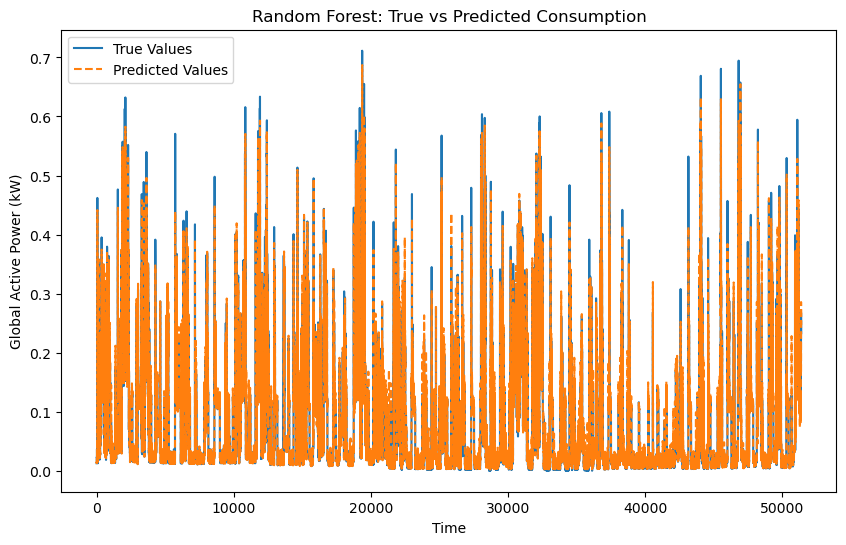

In [53]:
# رسم پیش‌بینی‌ها
plt.figure(figsize=(10, 6))
plt.plot(y_test, label='True Values')
plt.plot(y_pred, label='Predicted Values', linestyle='dashed')
plt.xlabel('Time')
plt.ylabel('Global Active Power (kW)')
plt.title('Random Forest: True vs Predicted Consumption')
plt.legend()
plt.show()

In [54]:
last_data_point = scaled_data[-24:]  # آخرین داده‌ها از ۲۰۰۷
current_input = last_data_point.reshape(1, 24)

predictions_2008 = []

# پیش‌بینی برای 180 روز (6 ماه)
for _ in range(180):
    next_pred = model.predict(current_input)
    predictions_2008.append(next_pred[0])
    current_input = np.append(current_input[:, 1:], next_pred.reshape(1, 1), axis=1)

In [55]:
# بازگشت به مقیاس واقعی
predicted_values_2008 = scaler.inverse_transform(np.array(predictions_2008).reshape(-1, 1))

# ایجاد تاریخ برای پیش‌بینی‌ها (۶ ماه اول ۲۰۰۸)
predicted_dates = pd.date_range(start='2008-01-01', periods=180, freq='D')

# ایجاد دیتافریم برای پیش‌بینی‌ها
predictions_df_2008 = pd.DataFrame(predicted_values_2008, columns=['Global_active_power'], index=predicted_dates)
# نمایش پیش‌بینی‌ها
print(predictions_df_2008)

            Global_active_power
2008-01-01             1.070834
2008-01-02             1.097132
2008-01-03             1.114139
2008-01-04             1.190529
2008-01-05             1.120858
...                         ...
2008-06-24             1.159476
2008-06-25             1.164164
2008-06-26             1.165162
2008-06-27             1.161879
2008-06-28             1.161845

[180 rows x 1 columns]


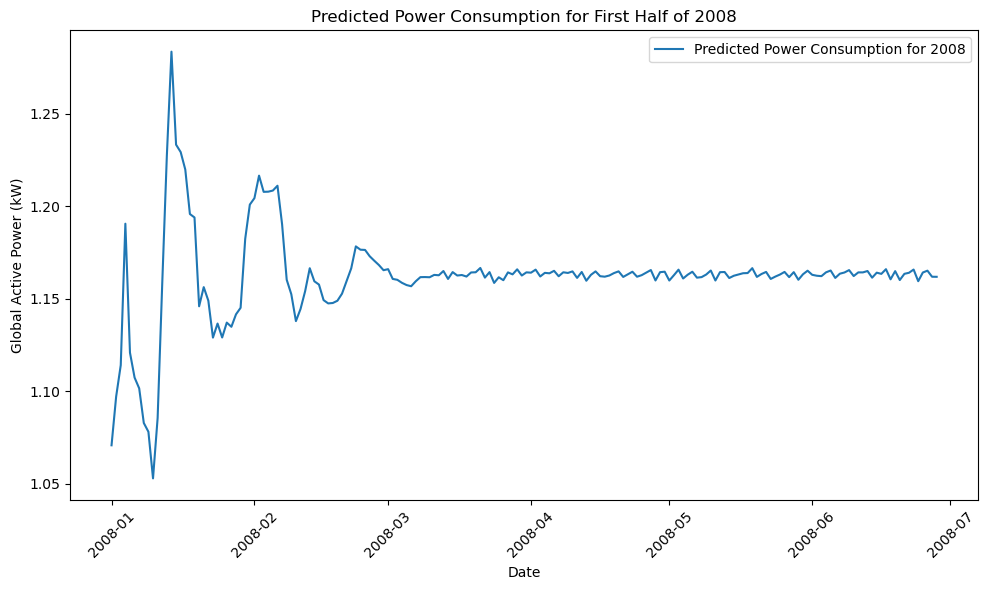

In [56]:
# رسم نمودار پیش‌بینی‌ها
plt.figure(figsize=(10, 6))
plt.plot(predictions_df_2008.index, predictions_df_2008['Global_active_power'], label='Predicted Power Consumption for 2008')
plt.xlabel('Date')
plt.ylabel('Global Active Power (kW)')
plt.title('Predicted Power Consumption for First Half of 2008')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [57]:

predictions_df_2008['Datetime'] = pd.to_datetime(predictions_df_2008.index)

predictions_df_2008

,Global_active_power,Datetime
2008-01-01,1.070834,2008-01-01
2008-01-02,1.097132,2008-01-02
2008-01-03,1.114139,2008-01-03
2008-01-04,1.190529,2008-01-04
2008-01-05,1.120858,2008-01-05
...,...,...
2008-06-24,1.159476,2008-06-24
2008-06-25,1.164164,2008-06-25
2008-06-26,1.165162,2008-06-26
2008-06-27,1.161879,2008-06-27


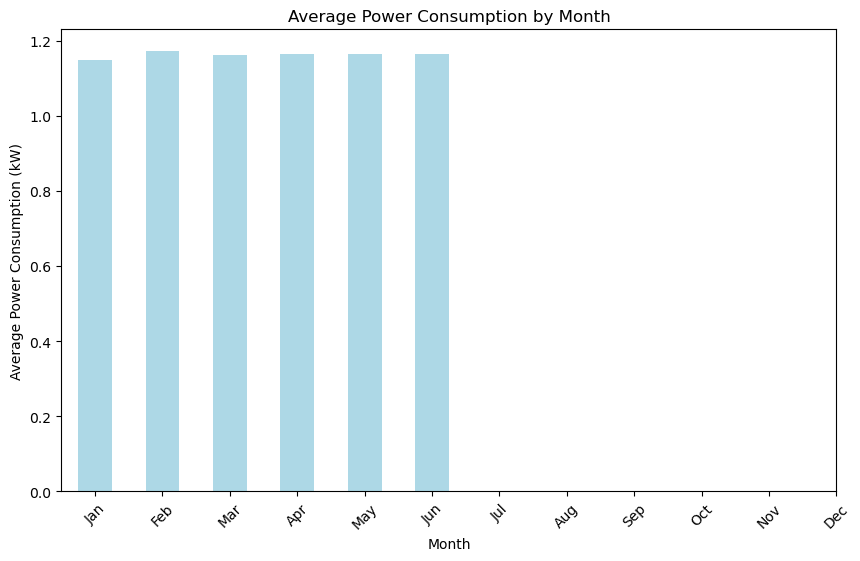

In [58]:
predictions_df_2008['Month'] = predictions_df_2008['Datetime'].dt.month
# گروه‌بندی داده‌ها بر اساس ماه و محاسبه میانگین مصرف برق
monthly_consumption = predictions_df_2008.groupby('Month')['Global_active_power'].mean()
# رسم نمودار
plt.figure(figsize=(10, 6))
monthly_consumption.plot(kind='bar', color='lightblue')
plt.title('Average Power Consumption by Month')
plt.xlabel('Month')
plt.ylabel('Average Power Consumption (kW)')
plt.xticks(ticks=range(12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], rotation=45)
plt.show()

In [59]:
# فیلتر کردن داده‌ها برای شش ماه اول سال 2007
data_2007 = data
# انتخاب ستون‌های مرتبط
data_2007 = data_2007[[ 'Global_intensity']]

# ست کردن Datetime به عنوان ایندکس برای تحلیل سری زمانی

# پر کردن مقادیر گمشده با استفاده از forward fill
data_2007.fillna(method='ffill', inplace=True)

# نرمال‌سازی داده‌ها
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data_2007[['Global_intensity']])

/var/folders/v6/4xftr67s587g9mx0pnkfxpbw0000gn/T/ipykernel_6573/656010232.py:9: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_2007.fillna(method='ffill', inplace=True)
/var/folders/v6/4xftr67s587g9mx0pnkfxpbw0000gn/T/ipykernel_6573/656010232.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_2007.fillna(method='ffill', inplace=True)


In [60]:
# ایجاد داده‌ها برای آموزش
X, y = create_dataset(scaled_data, time_step=24)

# تقسیم داده‌ها به داده‌های آموزشی و تست (80% آموزش، 20% تست)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [61]:
# آموزش مدل Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# پیش‌بینی
y_pred = model.predict(X_test)


In [62]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root Mean Squared Error (RMSE): {rmse}")

Mean Absolute Error (MAE): 0.010753492898420858
Mean Squared Error (MSE): 0.0007348628771868421
Root Mean Squared Error (RMSE): 0.02710835437991104


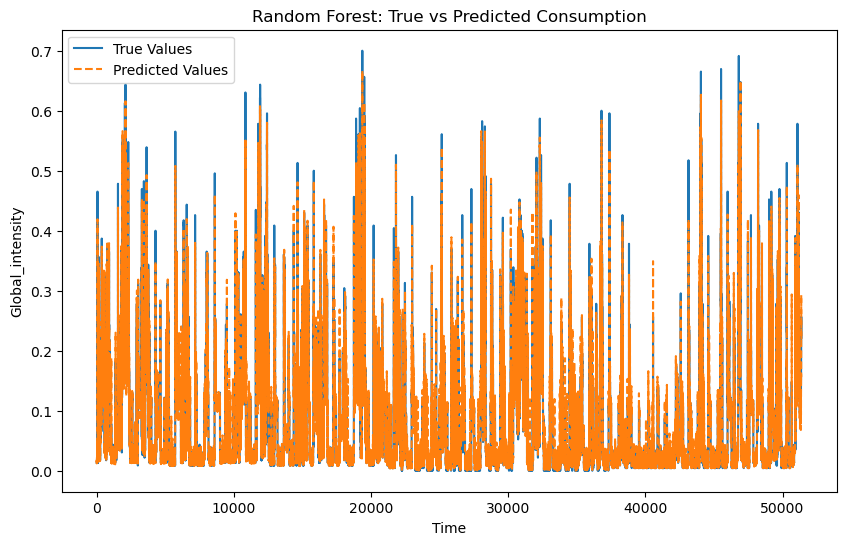

In [63]:
# رسم پیش‌بینی‌ها
plt.figure(figsize=(10, 6))
plt.plot(y_test, label='True Values')
plt.plot(y_pred, label='Predicted Values', linestyle='dashed')
plt.xlabel('Time')
plt.ylabel('Global_intensity')
plt.title('Random Forest: True vs Predicted Consumption')
plt.legend()
plt.show()

In [64]:
last_data_point = scaled_data[-24:]  # آخرین داده‌ها از ۲۰۰۷
current_input = last_data_point.reshape(1, 24)

predictions_2008 = []

# پیش‌بینی برای 180 روز (6 ماه)
for _ in range(180):
    next_pred = model.predict(current_input)
    predictions_2008.append(next_pred[0])
    current_input = np.append(current_input[:, 1:], next_pred.reshape(1, 1), axis=1)